# Step 4 – Final experiments for the report
**COMP8240 project – reproducing Wang et al. (WWW '21), "Mixup for Node and Graph Classification"**

This notebook adds the work requested after the project update ("the new dataset construction and testing need more work; some results need better explanation"). It does **not** rebuild anything: it loads the arXiv citation graph saved by the Step 3 notebook and re-uses, unchanged, the model and Mixup code of the Table 3 reproduction notebook, with the same random splits and seeds.

| Part | What it produces | Needs | Time (T4) |
|---|---|---|---|
| 2–3 | Data snippets, dataset statistics and homophily for all datasets (report figures) | – | 2 min |
| 4 | Blind annotation sheets, then **Cohen's kappa** (human vs arXiv labels, human vs human) | your annotation sheet | 2 min + annotation time |
| 5 | **Gemini as an independent annotator** on the annotation sample, kappa against the humans and arXiv | Gemini key in Colab Secrets | 5 min |
| 6 | arXiv graph: MLP / GCN / JKNet / GraphConv / GAT, each ± Mixup, accuracy **and macro-F1**, per-class F1, label-rate study | GPU | 45–60 min |
| 7 | **LLM-as-a-judge** of the best model's mistakes (genuine error or ambiguous paper?) | Gemini | 10 min |
| 8 | Explaining the replication: α × layer type on Cora/Citeseer/Pubmed, Amazon convergence, training curves | GPU | 70–90 min |
| 9 | All tables and figures in one zip for the report and the GitHub repo | – | 1 min |

**Inputs (written by Step 3 to Google Drive, `MyDrive/mixup_reproduction/paper_graph/`):** `paper_graph.pt`, `papers.csv`, and your filled annotation sheet.
**Outputs:** everything goes to `MyDrive/mixup_reproduction/step4/` (`figures/`, `tables/`, result files).

**How to run**
1. Runtime → Change runtime type → **T4 GPU**.
2. Put your Gemini key in **Colab Secrets** (key icon on the left → *Add new secret* → name `GEMINI_API_KEY` → switch on *Notebook access*). The key is never written into this notebook, so the notebook can go in the public repo.
3. Optional smoke test: set `QUICK = True` in 1.3 and run everything (≈ 10 min, tiny settings, results kept in a separate file). Then set it back to `False`.
4. Run Sections 1–4.2 first, so the blind annotation sheets are ready. The GPU sections (6, 8) can run while you annotate.

Every training run is cached in a results file and every Gemini answer in `llm_cache.jsonl`, so after a disconnect just re-run: finished work is skipped.

---
## 1. Setup
### 1.1 Install

In [1]:
%pip install -q torch_geometric google-genai

### 1.2 Imports and version log

In [2]:
import os, os.path as osp, re, json, math, time, random, hashlib, platform, shutil, warnings
import xml.etree.ElementTree as ET
from types import SimpleNamespace

import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import cohen_kappa_score, f1_score, confusion_matrix
from tqdm.auto import tqdm

import torch_geometric
import torch_geometric.transforms as T
from torch_geometric.datasets import Planetoid, Amazon
from torch_geometric.nn import GATConv

warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_colwidth', 120)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ENV = {'python': platform.python_version(), 'torch': torch.__version__, 'torch_geometric': torch_geometric.__version__,
       'numpy': np.__version__, 'cuda': torch.version.cuda,
       'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'}
for k, v in ENV.items():
    print(f'{k:>16}: {v}')

          python: 3.13.16
           torch: 2.11.0+cu130
 torch_geometric: 2.8.1
           numpy: 2.4.6
            cuda: 13.0
             gpu: Tesla T4


### 1.3 Settings
Switch parts on or off with the `RUN_*` flags. The experimental settings are the same as the Table 3 reproduction (hidden 256, dropout 0.4, Adam lr 1e-3, 300 epochs, random 60/20/20 splits with fixed seeds, test accuracy at the best-validation epoch).

In [3]:
QUICK = False                  # True = smoke test with tiny settings (separate results file)
USE_DRIVE = True

# ---- which parts to run ----
RUN_SNIPPETS     = True        # Section 3
RUN_ANNOTATION   = True        # Section 4
RUN_LLM          = True        # Sections 5 and 7.3 (Gemini)
RUN_ARXIV_TESTS  = True        # Section 6.3-6.6
RUN_LABEL_RATE   = True        # Section 6.7
RUN_ERROR_STUDY  = True        # Section 7
RUN_ALPHA_CHECK  = True        # Section 8.1
RUN_AMAZON_CHECK = True        # Section 8.2
RUN_CURVES       = True        # Section 8.3

# ---- annotation (Section 4) ----
A1_FILE = None                 # your filled annotation sheet; None = search the usual names in the paper_graph folder
HELPER_N = 25                  # papers in the optional second-annotator sheet
OVERWRITE_BLIND = False        # never overwrite a blind sheet that may already contain answers

# ---- Gemini (Sections 5 and 7) ----
GEMINI_MODEL = 'gemini-3.8-flash'   # if this model is retired, the replacement Google suggests is used and printed
LLM_BATCH = 10                 # papers per labelling request
JUDGE_BATCH = 45               # papers per judging request (free tier allows only ~20 requests per model per day)
LLM_PAUSE = 7.0                # seconds between requests (free tier allows only a few requests per minute)
JUDGE_MAX_ERRORS = 120         # model mistakes sent to the judge
CONTROL_N = 40                 # control items: correct papers paired with a random wrong label

# ---- training (same as the Table 3 reproduction) ----
HP     = dict(hidden=256, dropout=0.4, lr=1e-3, weight_decay=0.0, epochs=300)
GAT_HP = dict(hidden=8, heads=8, dropout=0.6, lr=5e-3, weight_decay=5e-4, epochs=300)
MIXUP_ALPHA = 1.0              # paper default; '... a4' methods use alpha = 4 as in the released code
DROPEDGE_P = 0.3

# Section 6: arXiv graph
AX_METHODS = ['MLP', 'Mixup+MLP', 'GCN', 'Mixup+GCN', 'DropEdge+GCN', 'JKNet', 'Mixup+JKNet',
              'GraphConv', 'Mixup+GraphConv', 'Mixup+GraphConv a4', 'GAT']
AX_SPLITS, AX_SEEDS, AX_DEPTHS = 10, 3, [2, 3]
LABEL_RATES = [0.05, 0.1, 0.2, 0.3, 0.6]       # share of ALL nodes used for training (0.6 = main protocol)
LR_METHODS  = ['MLP', 'GCN', 'Mixup+GCN', 'GraphConv', 'Mixup+GraphConv a4']
LR_SPLITS, LR_SEEDS, LR_DEPTH = 10, 2, 2
JUDGE_METHOD, JUDGE_SPLIT = None, 0            # None = method with the best validation accuracy in Section 6

# Section 8: explaining the replication
ALPHA_DATASETS = ['Cora', 'Citeseer', 'Pubmed']
ALPHA_METHODS  = ['GCN', 'Mixup+GCN', 'Mixup+GCN a4', 'GraphConv', 'Mixup+GraphConv', 'Mixup+GraphConv a4']
ALPHA_SPLITS, ALPHA_SEEDS, ALPHA_DEPTH = 10, 3, 3          # depth 3 = released code
AMZ_DATASETS = ['Computers', 'Photo']
AMZ_METHODS  = ['GCN', 'Mixup+GCN', 'GraphConv', 'Mixup+GraphConv a4']
AMZ_SPLITS, AMZ_SEEDS, AMZ_DEPTH, AMZ_EPOCHS, AMZ_CAP = 5, 2, 2, 1000, 300

if QUICK:
    HP['epochs'], GAT_HP['epochs'] = 30, 30
    AX_SPLITS, AX_SEEDS, AX_DEPTHS = 2, 1, [2]
    LABEL_RATES, LR_SPLITS, LR_SEEDS = [0.1, 0.6], 1, 1
    ALPHA_DATASETS, ALPHA_SPLITS, ALPHA_SEEDS = ['Cora'], 1, 1
    AMZ_DATASETS, AMZ_SPLITS, AMZ_SEEDS, AMZ_EPOCHS, AMZ_CAP = ['Photo'], 1, 1, 60, 30
    JUDGE_MAX_ERRORS, CONTROL_N = 10, 5

# ---- folders ----
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/mixup_reproduction'
else:
    BASE = './mixup_reproduction'
PG_DIR = osp.join(BASE, 'paper_graph')          # written by Step 3
OUT = osp.join(BASE, 'step4')
FIG, TAB = osp.join(OUT, 'figures'), osp.join(OUT, 'tables')
DATA_DIR = './data'
for d in (OUT, FIG, TAB, DATA_DIR):
    os.makedirs(d, exist_ok=True)
print('inputs :', PG_DIR, sorted(os.listdir(PG_DIR)) if osp.exists(PG_DIR) else '(missing!)')
print('outputs:', OUT, '| QUICK =', QUICK)

Mounted at /content/drive
inputs : /content/drive/MyDrive/mixup_reproduction/paper_graph ['annotation_sheet.csv', 'annotation_sheet.gsheet', 'annotation_sheet_filled.csv', 'annotation_sheet_filled.gsheet', 'api_cache', 'dataset_card.json', 'edges.csv', 'paper_graph.pt', 'paper_graph_mixup_gain.csv', 'paper_graph_results.jsonl', 'paper_graph_results_summary.csv', 'papers.csv', 'step4_results.jsonl']
outputs: /content/drive/MyDrive/mixup_reproduction/step4 | QUICK = False


### 1.4 Shared code from the Table 3 reproduction notebook (unchanged)
Sparse aggregation utilities and the two-stage Mixup model (Algorithm 1 of the paper), copied without changes so the new results are directly comparable with the replication. The model was checked against the authors' released code in Section 5 of that notebook (max. difference ≈ 1e-7).

In [4]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def edge_index_to_csr(edge_index, num_nodes):
    """CSR with rows = target nodes (edge_index[1]) and columns = source nodes (edge_index[0]).
    Self-loops and duplicate edges are removed."""
    src, tgt = edge_index[0].long(), edge_index[1].long()
    key = tgt * num_nodes + src
    key = torch.unique(key[src != tgt])          # sorted by (target, source), no duplicates
    tgt, src = key // num_nodes, key % num_nodes
    rowptr = torch.zeros(num_nodes + 1, dtype=torch.long)
    rowptr[1:] = torch.cumsum(torch.bincount(tgt, minlength=num_nodes), 0)
    return rowptr, src


def rowptr_from_rows(rows, n):
    rowptr = torch.zeros(n + 1, dtype=torch.long)
    rowptr[1:] = torch.cumsum(torch.bincount(rows, minlength=n), 0)
    return rowptr


def csr_rows(rowptr):
    return torch.repeat_interleave(torch.arange(rowptr.numel() - 1), rowptr.diff())


def agg_weights(kind, row, col, n, deg=None):
    """Neighbour edge weights and per-node self weights for one aggregation scheme."""
    if deg is None:
        deg = torch.bincount(row, minlength=n)
    deg = deg.float()
    if kind == 'gcn':
        dinv = (deg + 1.0).rsqrt()
        return dinv[row] * dinv[col], 1.0 / (deg + 1.0)
    if kind == 'graphconv':
        return 1.0 / deg[row].clamp(min=1.0), torch.zeros(n)
    raise ValueError(kind)


class GraphOps:
    """Sparse neighbour-aggregation operator  h -> A @ h  plus per-node self weights."""
    def __init__(self, rowptr, col, val, n, self_w, device, max_nnz=50_000_000):
        self.n, self.device = n, device
        self.self_w = self_w.to(device)
        if col.numel() <= max_nnz:          # small enough: one COO matrix on the device (supports autograd)
            idx = torch.stack([csr_rows(rowptr), col])
            self.A = torch.sparse_coo_tensor(idx, val, (n, n)).coalesce().to(device)
            self.blocks = None
        else:                               # huge graph: keep CSR on the CPU and multiply in row blocks (inference only)
            self.A = None
            self.rowptr, self.col, self.val = rowptr, col, val
            self.blocks, s = [], 0
            while s < n:
                e = int(torch.searchsorted(rowptr, rowptr[s] + max_nnz, right=True)) - 1
                e = min(max(e, s + 1), n)
                self.blocks.append((s, e))
                s = e

    def agg(self, h):
        if self.A is not None:
            return torch.sparse.mm(self.A, h)
        out = torch.empty(self.n, h.size(1), device=h.device, dtype=h.dtype)
        for s, e in self.blocks:
            p0, p1 = int(self.rowptr[s]), int(self.rowptr[e])
            crow = (self.rowptr[s:e + 1] - p0).to(h.device)
            blk = torch.sparse_csr_tensor(crow, self.col[p0:p1].to(h.device), self.val[p0:p1].to(h.device),
                                          (e - s, self.n))
            out[s:e] = blk @ h
        return out


def make_graph(rowptr, col, n, kind, device, deg=None, edge_scale=None):
    val, self_w = agg_weights(kind, csr_rows(rowptr), col, n, deg)
    if edge_scale is not None:
        val = val * edge_scale
    return GraphOps(rowptr, col, val.float(), n, self_w.float(), device)


def drop_edge_undirected(edge_index, p):
    """DropEdge (Rong et al., 2020): remove a random fraction p of undirected edges."""
    src, dst = edge_index
    und = edge_index[:, src < dst]
    und = und[:, torch.rand(und.size(1)) >= p]
    return torch.cat([und, und.flip(0)], dim=1)


@torch.no_grad()
def micro_f1(logits, y, multilabel):
    """F1-micro. For single-label tasks this equals accuracy."""
    if not multilabel:
        return (logits.argmax(1) == y).float().mean().item()
    pred, y = logits > 0, y.bool()
    tp = (pred & y).sum().item()
    fp = (pred & ~y).sum().item()
    fn = (~pred & y).sum().item()
    return 2 * tp / max(2 * tp + fp + fn, 1)

print('utilities ready')

utilities ready


In [5]:
class MixConv(nn.Module):
    """One graph-convolution layer split into a neighbour part and a self (centre) part."""
    def __init__(self, d_in, d_out, kind):
        super().__init__()
        self.kind = kind
        self.lin = nn.Linear(d_in, d_out, bias=False)          # neighbour transform (shared with self term for GCN)
        if kind == 'gcn':
            self.bias = nn.Parameter(torch.zeros(d_out))
            nn.init.xavier_uniform_(self.lin.weight)
        else:
            self.root = nn.Linear(d_in, d_out, bias=True)      # separate root transform (GraphConv / SAGE)

    def forward(self, G, h):                                    # ordinary layer
        if self.kind == 'gcn':
            hw = self.lin(h)
            return G.agg(hw) + G.self_w.unsqueeze(1) * hw + self.bias
        return G.agg(self.lin(h)) + self.root(h)

    def neighbours(self, G, h_stage1):                          # aggregated messages from stage-one reps
        return G.agg(self.lin(h_stage1))

    def centre_pair(self, h_mix, sw_i, sw_j):                   # self terms for branch i and branch j
        if self.kind == 'gcn':
            hw = self.lin(h_mix)
            return sw_i.unsqueeze(1) * hw + self.bias, sw_j.unsqueeze(1) * hw + self.bias
        c = self.root(h_mix)
        return c, c


class TwoStageMixupGNN(nn.Module):
    def __init__(self, in_dim, hidden, out_dim, num_layers, kind='gcn', jk=None, dropout=0.5):
        super().__init__()
        self.convs = nn.ModuleList([MixConv(in_dim if l == 0 else hidden, hidden, kind) for l in range(num_layers)])
        self.kind, self.jk, self.dropout = kind, jk, dropout
        self.cls = nn.Linear(hidden * num_layers if jk == 'cat' else hidden, out_dim)

    def _post(self, h):
        return F.dropout(F.relu(h), self.dropout, self.training)

    def _readout(self, hs):
        if self.jk == 'cat':
            h = torch.cat(hs, dim=1)
        elif self.jk == 'max':
            h = torch.stack(hs, 0).max(0).values
        else:
            h = hs[-1]
        return self.cls(h)

    def forward(self, x, G):
        hs, h = [], x
        for conv in self.convs:
            h = self._post(conv(G, h))
            hs.append(h)
        return self._readout(hs)

    def forward_mixup(self, x, G, lam, perm):
        # ---- Stage 1: feed-forward without Mixup (Alg. 1, lines 1-8) ----
        stage1, h = [x], x
        for conv in self.convs[:-1]:
            h = self._post(conv(G, h))
            stage1.append(h)
        # ---- Stage 2: two-branch Mixup graph convolutions (lines 9-20) ----
        h_mix = lam * x + (1 - lam) * x[perm]                   # Eq. (5)
        sw_i, sw_j = G.self_w, G.self_w[perm]
        outs = []
        for l, conv in enumerate(self.convs):
            nb = conv.neighbours(G, stage1[l])                   # messages from stage-one neighbours
            c_i, c_j = conv.centre_pair(h_mix, sw_i, sw_j)
            h_i = F.relu(nb + c_i)                               # branch on node i's topology   (Eq. 6)
            h_j = F.relu(nb[perm] + c_j)                         # branch on node j's topology   (Eq. 6)
            h_mix = F.dropout(lam * h_i + (1 - lam) * h_j, self.dropout, self.training)   # Eq. (7)
            outs.append(h_mix)
        return self._readout(outs)


class GATNet(nn.Module):
    """2-layer GAT baseline (Velickovic et al., 2018) for Table 3."""
    def __init__(self, in_dim, out_dim, hidden=8, heads=8, dropout=0.6):
        super().__init__()
        self.dropout = dropout
        self.c1 = GATConv(in_dim, hidden, heads=heads, dropout=dropout)
        self.c2 = GATConv(hidden * heads, out_dim, heads=1, concat=False, dropout=dropout)

    def forward(self, x, edge_index):
        x = F.dropout(x, self.dropout, self.training)
        x = F.elu(self.c1(x, edge_index))
        x = F.dropout(x, self.dropout, self.training)
        return self.c2(x, edge_index)

print('models ready')

models ready


### 1.5 Small helpers: result store, saving tables and figures

In [6]:
class ResultStore:
    """Append-only JSON-lines store keyed by a run identifier (finished runs are skipped on re-run)."""
    def __init__(self, path):
        self.path, self.rows = path, {}
        if osp.exists(path):
            with open(path) as f:
                for line in f:
                    if line.strip():
                        r = json.loads(line)
                        self.rows[r['key']] = r

    def __contains__(self, key):
        return key in self.rows

    def put(self, key, rec):
        rec = dict(rec, key=key)
        self.rows[key] = rec
        with open(self.path, 'a') as f:
            f.write(json.dumps(rec) + '\n')

    def frame(self, prefix):
        return pd.DataFrame([r for k, r in self.rows.items() if k.startswith(prefix)])


STORE = ResultStore(osp.join(OUT, 'step4_results_quick.jsonl' if QUICK else 'step4_results.jsonl'))
print(f'results file: {STORE.path} ({len(STORE.rows)} runs stored)')


def save_table(df, name, index=False):
    """CSV (for the repo) + LaTeX (for Overleaf)."""
    df.to_csv(osp.join(TAB, name + '.csv'), index=index)
    try:
        with open(osp.join(TAB, name + '.tex'), 'w') as f:
            f.write(df.to_latex(index=index, escape=True))
    except Exception as e:                       # to_latex needs jinja2; the CSV is enough without it
        print('(LaTeX export skipped:', e, ')')


def save_fig(fig, name):
    fig.savefig(osp.join(FIG, name + '.png'), dpi=200, bbox_inches='tight')
    fig.savefig(osp.join(FIG, name + '.pdf'), bbox_inches='tight')
    plt.show()


def table_figure(df, name, title, col_widths=None, fontsize=8):
    """Render a small DataFrame as a figure (data snippets for the report)."""
    fig, ax = plt.subplots(figsize=(12, 0.32 * len(df) + 0.9))
    ax.axis('off')
    t = ax.table(cellText=df.astype(str).values, colLabels=list(df.columns), loc='center',
                 cellLoc='left', colLoc='left', colWidths=col_widths)
    t.auto_set_font_size(False)
    t.set_fontsize(fontsize)
    t.scale(1, 1.35)
    for (r, c), cell in t.get_celld().items():
        cell.set_edgecolor('#bbbbbb')
        if r == 0:
            cell.set_text_props(weight='bold')
            cell.set_facecolor('#eeeeee')
    ax.set_title(title, fontsize=10, loc='left')
    save_fig(fig, name)

print('helpers ready')

results file: /content/drive/MyDrive/mixup_reproduction/step4/step4_results.jsonl (1750 runs stored)
helpers ready


---
## 2. Load the datasets
### 2.1 The arXiv citation graph (from Step 3)
`paper_graph.pt` holds the node features (MiniLM embeddings of title + abstract), labels (arXiv primary category) and citation edges of the largest connected component; `papers.csv` has one row per node in the same order.

In [7]:
_saved = torch.load(osp.join(PG_DIR, 'paper_graph.pt'), weights_only=False)
_g = _saved['main']
CLASSES = list(_g['classes'])
_ei = _g['edge_index'].long()
_ei = torch.cat([_ei, _ei.flip(0)], dim=1)                     # undirected
ARXIV = SimpleNamespace(name='arXiv', x=_g['x'].float(), y=_g['y'].long(), edge_index=_ei, n=_g['x'].size(0),
                        num_features=_g['x'].size(1), num_classes=len(CLASSES), graphs={})
ARXIV.rowptr, ARXIV.col = edge_index_to_csr(ARXIV.edge_index, ARXIV.n)

papers = pd.read_csv(osp.join(PG_DIR, 'papers.csv'), dtype={'arxiv_id': str})
assert len(papers) == ARXIV.n, 'papers.csv and paper_graph.pt do not match'
if (papers.arxiv_id.values != np.array(_g['arxiv_ids'])).any():
    print('note: arXiv ids in papers.csv differ in format from paper_graph.pt – using the ids from paper_graph.pt')
    papers['arxiv_id'] = list(_g['arxiv_ids'])
papers['node'] = np.arange(ARXIV.n)
CODE_OF = dict(zip(papers.label, papers.label_code)) if 'label_code' in papers else {}
print(f'arXiv graph: {ARXIV.n} nodes, {ARXIV.col.numel() // 2} undirected edges, {ARXIV.num_features}-d features '
      f'({_saved.get("feature_method", "?")}), classes: {CLASSES}')

arXiv graph: 2813 nodes, 19936 undirected edges, 384-d features (sentence-transformers/all-MiniLM-L6-v2), classes: ['Computer vision', 'Info. retrieval', 'Machine learning', 'NLP', 'Robotics', 'Security']


### 2.2 Abstracts from the arXiv API
`papers.csv` does not store abstracts, but the annotators and the LLM need them. They are fetched once from the arXiv API (≈ 30 requests, 3 s apart as arXiv asks) and cached in `step4/abstracts.json`. arXiv metadata is released under CC0.

In [8]:
ABS_PATH = osp.join(OUT, 'abstracts.json')
ABSTRACTS = json.load(open(ABS_PATH)) if osp.exists(ABS_PATH) else {}
_ATOM = '{http://www.w3.org/2005/Atom}'


def fetch_abstracts(ids, batch=100):
    todo = [a for a in ids if a not in ABSTRACTS]
    sess = requests.Session()
    sess.headers['User-Agent'] = 'COMP8240-mixup-reproduction (student project)'
    for i in tqdm(range(0, len(todo), batch), desc='arXiv API'):
        chunk = todo[i:i + batch]
        for attempt in range(5):
            try:
                r = sess.get('https://export.arxiv.org/api/query',
                             params={'id_list': ','.join(chunk), 'max_results': len(chunk)}, timeout=120)
                if r.status_code == 200:
                    break
            except requests.RequestException:
                pass
            time.sleep(5 * 2 ** attempt)
        else:
            print('arXiv API not reachable for one batch – continuing without it')
            continue
        for e in ET.fromstring(r.text).findall(_ATOM + 'entry'):
            m = re.search(r'arxiv\.org/abs/(.+?)(v\d+)?$', e.findtext(_ATOM + 'id') or '')
            if m:
                ABSTRACTS[m.group(1)] = ' '.join((e.findtext(_ATOM + 'summary') or '').split())
        json.dump(ABSTRACTS, open(ABS_PATH, 'w'))
        time.sleep(3.1)


fetch_abstracts(papers.arxiv_id.tolist())
papers['abstract'] = papers.arxiv_id.map(ABSTRACTS).fillna('')
print(f'abstracts available for {(papers.abstract.str.len() > 0).sum()} / {len(papers)} papers')

arXiv API: 0it [00:00, ?it/s]

abstracts available for 2813 / 2813 papers


### 2.3 The original datasets (same loader and preprocessing as the reproduction)
Planetoid citation graphs (Cora, Citeseer, Pubmed; Yang et al., 2016) and the Amazon co-purchase graphs (Computers, Photo; Shchur et al., 2018), with row-normalised features.

In [9]:
PYG_NAME = {'Cora': 'Cora', 'Citeseer': 'CiteSeer', 'Pubmed': 'PubMed'}
_CACHE = {'arXiv': ARXIV}


def load_dataset(name):
    if name in _CACHE:
        return _CACHE[name]
    if name in PYG_NAME:
        ds = Planetoid(osp.join(DATA_DIR, 'Planetoid'), PYG_NAME[name], transform=T.NormalizeFeatures())
    elif name in ('Computers', 'Photo'):
        ds = Amazon(osp.join(DATA_DIR, 'Amazon'), name, transform=T.NormalizeFeatures())
    else:
        raise ValueError(name)
    d = ds[0]
    rowptr, col = edge_index_to_csr(d.edge_index, d.num_nodes)
    D = SimpleNamespace(name=name, x=d.x, y=d.y, edge_index=d.edge_index, rowptr=rowptr, col=col, n=d.num_nodes,
                        num_features=ds.num_features, num_classes=ds.num_classes, graphs={}, raw_dir=ds.raw_dir)
    _CACHE[name] = D
    return D


def make_split(n, split_id, train=0.6, val=0.2):
    """Identical to the reproduction notebook: split s always gives the same 60/20/20 partition."""
    rng = np.random.RandomState(1000 + split_id)
    perm = rng.permutation(n)
    a, b = int(train * n), int((train + val) * n)
    return {k: torch.from_numpy(v).long() for k, v in
            {'train': perm[:a], 'val': perm[a:b], 'test': perm[b:]}.items()}


def edge_homophily(D):
    rows = csr_rows(D.rowptr)
    return (D.y[rows] == D.y[D.col]).float().mean().item()

print('loaders ready')

loaders ready


---
## 3. Data snippets and statistics (report: "Original datasets" and "Construction of new data")
### 3.1 Statistics of every dataset used
**Edge homophily** = share of edges joining two nodes with the same label. GNNs, and the neighbourhood-based Mixup, rely on it, so it is a key number for explaining the results.

In [10]:
if RUN_SNIPPETS:
    rows = []
    feat_type = {'Cora': 'bag of words (binary)', 'Citeseer': 'bag of words (binary)', 'Pubmed': 'TF-IDF',
                 'Computers': 'bag of words (reviews)', 'Photo': 'bag of words (reviews)', 'arXiv': 'MiniLM sentence embedding'}
    domain = {'Cora': 'citation', 'Citeseer': 'citation', 'Pubmed': 'citation', 'Computers': 'co-purchase',
              'Photo': 'co-purchase', 'arXiv': 'citation (new)'}
    for name in ['Cora', 'Citeseer', 'Pubmed', 'Computers', 'Photo', 'arXiv']:
        D = load_dataset(name)
        deg = D.rowptr.diff().float()
        rows.append({'Dataset': name, 'Domain': domain[name], 'Nodes': D.n, 'Edges': D.col.numel() // 2,
                     'Features': D.num_features, 'Feature type': feat_type[name], 'Classes': D.num_classes,
                     'Avg. degree': round(deg.mean().item(), 1),
                     'Largest class': f'{100 * torch.bincount(D.y).max().item() / D.n:.1f}%',
                     'Edge homophily': round(edge_homophily(D), 3)})
    dataset_stats = pd.DataFrame(rows)
    save_table(dataset_stats, 'dataset_statistics')
    display(dataset_stats)

Processing...
Done!
Processing...
Done!
Processing...
Done!
Processing...
Done!
Processing...
Done!


,Dataset,Domain,Nodes,Edges,Features,Feature type,Classes,Avg. degree,Largest class,Edge homophily
0,Cora,citation,2708,5278,1433,bag of words (binary),7,3.9,30.2%,0.810
1,Citeseer,citation,3327,4552,3703,bag of words (binary),6,2.7,21.1%,0.736
2,Pubmed,citation,19717,44324,500,TF-IDF,3,4.5,39.9%,0.802
3,Computers,co-purchase,13752,245861,767,bag of words (reviews),10,35.8,37.5%,0.777
4,Photo,co-purchase,7650,119081,745,bag of words (reviews),8,31.1,25.4%,0.827
5,arXiv,citation (new),2813,19936,384,MiniLM sentence embedding,6,14.2,35.6%,0.636


### 3.2 Snippet of an original dataset (Cora)
The Planetoid files (`ind.cora.x`, `.tx`, `.allx`, `.y`, `.ty`, `.ally`, `.graph`, `.test.index`) are pickled sparse matrices and an adjacency dictionary; PyTorch Geometric turns them into a feature matrix, a label vector and an edge list. The figure shows what one model input looks like.

raw files: ['ind.cora.allx', 'ind.cora.ally', 'ind.cora.graph', 'ind.cora.test.index', 'ind.cora.tx', 'ind.cora.ty', 'ind.cora.x', 'ind.cora.y']
as loaded: Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])


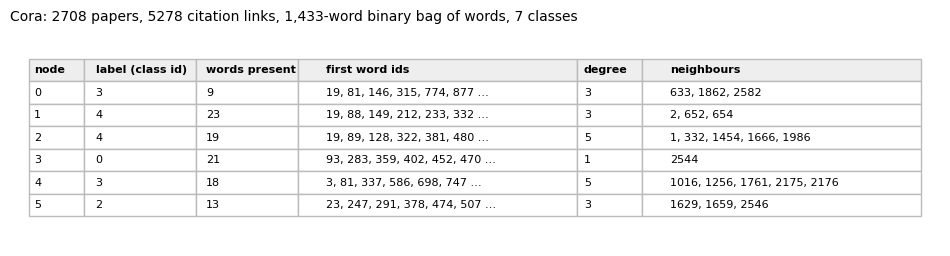

In [11]:
if RUN_SNIPPETS:
    D = load_dataset('Cora')
    raw = Planetoid(osp.join(DATA_DIR, 'Planetoid'), 'Cora')[0]          # un-normalised, to show word ids
    print('raw files:', sorted(os.listdir(D.raw_dir)))
    print('as loaded:', raw)
    snip = []
    for i in range(6):
        words = raw.x[i].nonzero().flatten().tolist()
        nb = D.col[D.rowptr[i]:D.rowptr[i + 1]].tolist()
        snip.append({'node': i, 'label (class id)': int(D.y[i]), 'words present': len(words),
                     'first word ids': ', '.join(map(str, words[:6])) + ' …',
                     'degree': len(nb), 'neighbours': ', '.join(map(str, nb[:5])) + (' …' if len(nb) > 5 else '')})
    cora_snip = pd.DataFrame(snip)
    save_table(cora_snip, 'snippet_cora')
    table_figure(cora_snip, 'snippet_cora',
                 f'Cora: {D.n} papers, {D.col.numel() // 2} citation links, 1,433-word binary bag of words, 7 classes',
                 col_widths=[0.06, 0.12, 0.11, 0.3, 0.07, 0.3])

### 3.3 Snippet of the new arXiv dataset
Top: five nodes as stored in `papers.csv` (the label is the arXiv primary category chosen by the authors). Bottom: rows of `edges.csv` (citation links between node ids).

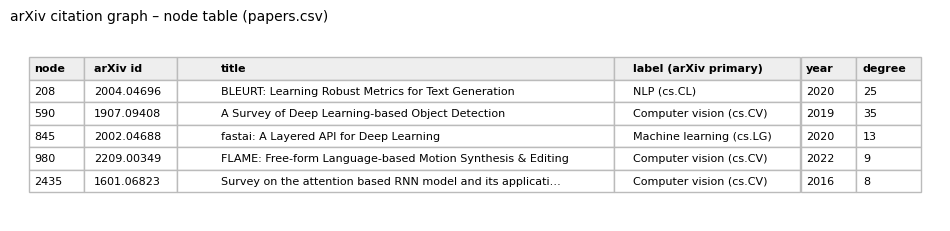

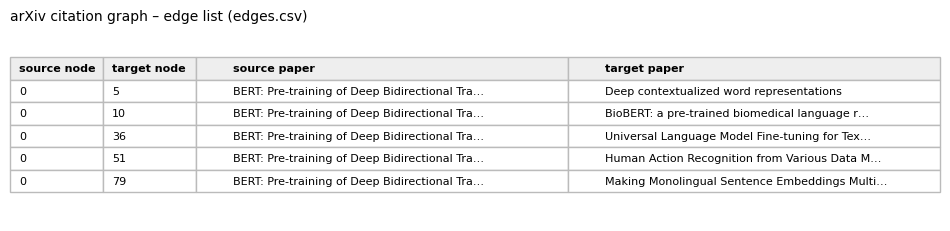

Example record
 ------------------------------------------------------------
arXiv id : 1810.04805
title    : BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding
label    : NLP
abstract : We introduce a new language representation model called BERT, which stands for Bidirectional Encoder Representations from Transformers. Unlike recent language representation models, BERT is designed to pre-train deep bidirectional representations from unlabeled text by jointly conditioning on both l…
feature  : 384-d MiniLM vector, first values [-0.101 -0.056  0.076  0.036]


In [12]:
if RUN_SNIPPETS:
    deg = ARXIV.rowptr.diff()
    ex = papers.sample(5, random_state=3).sort_values('node')
    ax_snip = pd.DataFrame({'node': ex.node, 'arXiv id': ex.arxiv_id,
                            'title': ex.title.map(lambda t: t if len(t) <= 58 else t[:57] + '…'),
                            'label (arXiv primary)': ex.label + ' (' + ex.get('label_code', '') + ')',
                            'year': ex.year.astype('Int64'), 'degree': deg[ex.node.values].numpy()})
    save_table(ax_snip, 'snippet_arxiv_nodes')
    table_figure(ax_snip, 'snippet_arxiv_nodes', 'arXiv citation graph – node table (papers.csv)',
                 col_widths=[0.06, 0.1, 0.47, 0.2, 0.06, 0.07])
    _e = _g['edge_index'][:, :5].T.numpy()
    short = lambda t, k=45: t if len(t) <= k else t[:k - 1] + '…'
    ax_edges = pd.DataFrame({'source node': _e[:, 0], 'target node': _e[:, 1],
                             'source paper': [short(papers.title[s]) for s in _e[:, 0]],
                             'target paper': [short(papers.title[t]) for t in _e[:, 1]]})
    save_table(ax_edges, 'snippet_arxiv_edges')
    table_figure(ax_edges, 'snippet_arxiv_edges', 'arXiv citation graph – edge list (edges.csv)',
                 col_widths=[0.1, 0.1, 0.4, 0.4])
    one = papers.loc[papers.abstract.str.len() > 0].iloc[0] if (papers.abstract.str.len() > 0).any() else papers.iloc[0]
    print('Example record\n', '-' * 60)
    print(f"arXiv id : {one.arxiv_id}\ntitle    : {one.title}\nlabel    : {one.label}\n"
          f"abstract : {one.abstract[:300]}…\nfeature  : 384-d MiniLM vector, first values {ARXIV.x[one.node, :4].numpy().round(3)}")

### 3.4 Class balance and degree distribution of the arXiv graph

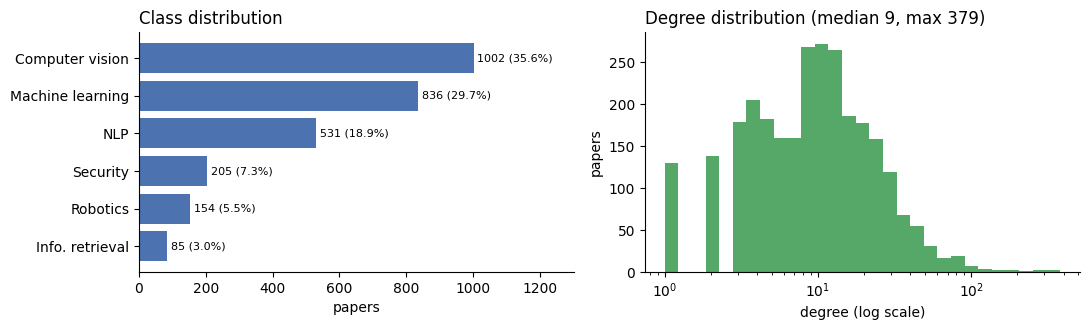

In [13]:
if RUN_SNIPPETS:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
    counts = papers.label.value_counts()
    axes[0].barh(counts.index[::-1], counts.values[::-1], color='#4C72B0')
    for i, v in enumerate(counts.values[::-1]):
        axes[0].text(v + 10, i, f'{v} ({100 * v / len(papers):.1f}%)', va='center', fontsize=8)
    axes[0].set_xlabel('papers')
    axes[0].set_title('Class distribution', loc='left')
    axes[0].set_xlim(0, counts.max() * 1.3)
    d = ARXIV.rowptr.diff().numpy()
    axes[1].hist(d, bins=np.logspace(0, np.log10(d.max() + 1), 30), color='#55A868')
    axes[1].set_xscale('log')
    axes[1].set_xlabel('degree (log scale)')
    axes[1].set_ylabel('papers')
    axes[1].set_title(f'Degree distribution (median {int(np.median(d))}, max {d.max()})', loc='left')
    for a in axes:
        a.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    save_fig(fig, 'arxiv_class_degree')

---
## 4. Human annotation and agreement
The labels come automatically from arXiv (the authors' own choice of primary category), so annotation here **validates** the labels rather than creating them. Three human views are possible:

| Rater | Papers | Blind to the arXiv label? |
|---|---|---|
| **You – checked** | the papers you already marked y/n in Step 3 | no (you saw the label) |
| **You – blind** | the rest of the annotation sample, labelled from title + abstract only | yes |
| **Helper – blind** (optional) | `HELPER_N` papers from your blind set, labelled by a second person | yes |

The checked set gives the simple agreement rate reported in the update; the blind sets give an unbiased **Cohen's kappa**, which corrects for agreement expected by chance (Cohen, 1960; interpreted with Landis & Koch, 1977).

### 4.1 Load your annotation sheet from Step 3

In [14]:
def norm_title(t):
    return re.sub(r'\W+', ' ', str(t).lower()).strip()


ID_SET = set(papers.arxiv_id)
TITLE2ID = {norm_title(t): a for t, a in zip(papers.title, papers.arxiv_id)}
LABEL_OF = dict(zip(papers.arxiv_id, papers.label))
TITLE_OF = dict(zip(papers.arxiv_id, papers.title))


def fix_id(raw, title=''):
    """Spreadsheets turn ids like 2203.05220 into the number 2203.0522 – recover the real id."""
    s = re.sub(r'v\d+$', '', str(raw).strip())
    if s in ID_SET:
        return s
    try:
        f = float(s)
        for d in (5, 4):
            if f'{f:.{d}f}' in ID_SET:
                return f'{f:.{d}f}'
    except ValueError:
        pass
    return TITLE2ID.get(norm_title(title))


_ALIAS = {c.lower(): c for c in CLASSES}
for c, code in CODE_OF.items():
    _ALIAS[str(code).lower()] = c
    _ALIAS[str(code).lower().replace('cs.', '')] = c
_ALIAS.update({'information retrieval': 'Info. retrieval', 'info retrieval': 'Info. retrieval', 'retrieval': 'Info. retrieval',
               'natural language processing': 'NLP', 'computation and language': 'NLP', 'language': 'NLP',
               'vision': 'Computer vision', 'cv': 'Computer vision', 'ml': 'Machine learning',
               'cryptography and security': 'Security', 'privacy': 'Security'})
_ALIAS = {k: v for k, v in _ALIAS.items() if v in CLASSES}


def norm_label(s):
    """Map a typed label (any case, arXiv code or common synonym) to a class name; None if empty/unknown."""
    if s is None or (isinstance(s, float) and np.isnan(s)):
        return None
    k = str(s).strip().lower().rstrip('.')
    if not k or k == 'nan':
        return None
    if k in _ALIAS:
        return _ALIAS[k]
    hits = [v for a, v in _ALIAS.items() if k.startswith(a) or a.startswith(k)]
    return hits[0] if len(set(hits)) == 1 else None


def read_sheet(path, sheet=0):
    df = pd.read_excel(path, sheet_name=sheet, dtype=str) if path.endswith('.xlsx') else pd.read_csv(path, dtype=str)
    df.columns = [str(c).strip().lower() for c in df.columns]
    return df


if RUN_ANNOTATION:
    if A1_FILE is None:
        names = ['annotation_sheet_filled.csv', 'annotation_sheet_filled.xlsx', 'annotation_sheet.xlsx', 'annotation_sheet.csv']
        found = [osp.join(d, n) for n in names for d in (PG_DIR, BASE, OUT) if osp.exists(osp.join(d, n))]
        A1_FILE = next((p for p in found if read_sheet(p).get('human_label_ok', pd.Series(dtype=str)).fillna('').str.strip().ne('').any()),
                       found[0] if found else None)
    assert A1_FILE, f'No annotation sheet found in {PG_DIR} – upload it there or set A1_FILE in 1.3'
    sheet = read_sheet(A1_FILE)
    sheet['arxiv_id'] = [fix_id(a, t) for a, t in zip(sheet.arxiv_id, sheet.title)]
    lost = sheet.arxiv_id.isna().sum()
    sheet = sheet.dropna(subset=['arxiv_id']).drop_duplicates('arxiv_id').reset_index(drop=True)
    sheet['arxiv_label'] = sheet.arxiv_id.map(LABEL_OF)
    ok = sheet.get('human_label_ok', pd.Series('', index=sheet.index)).fillna('').str.strip().str.lower().str[:1]
    sheet['checked'] = ok.isin(['y', 'n'])
    sheet['you_checked'] = np.where(ok == 'y', sheet.arxiv_label,
                                    np.where(ok == 'n', sheet.get('human_label', pd.Series(index=sheet.index)).map(norm_label), None))
    bad = sheet[(ok == 'n') & sheet.you_checked.isna()]
    print(f'{A1_FILE}: {len(sheet)} papers in the annotation sample ({lost} rows could not be matched to the graph)')
    print(f'already checked by you: {sheet.checked.sum()}  |  not yet annotated: {(~sheet.checked).sum()}')
    if len(bad):
        print('!! these "n" rows have a human_label that is not a class name – fix them in the sheet:')
        display(bad[['arxiv_id', 'title', 'human_label']])
    chk = sheet[sheet.checked]
    if len(chk):
        agree = (chk.you_checked == chk.arxiv_label).mean()
        print(f'checked set: you agreed with the arXiv label for {int((chk.you_checked == chk.arxiv_label).sum())}/{len(chk)} '
              f'papers ({100 * agree:.1f}%)')

/content/drive/MyDrive/mixup_reproduction/paper_graph/annotation_sheet_filled.csv: 102 papers in the annotation sample (0 rows could not be matched to the graph)
already checked by you: 50  |  not yet annotated: 52
checked set: you agreed with the arXiv label for 49/50 papers (98.0%)


### 4.2 Export the blind sheets
* `blind_sheet_you.xlsx` – the papers you have **not** annotated yet, without arXiv id, link or label.
* `blind_sheet_helper.xlsx` – optional: `HELPER_N` of those papers in a different order, for a second person.

Each file has a **Guide** tab (classes, keywords, decision rules) and a **Papers** tab with a drop-down for the label. Open the file from Drive with Google Sheets (or download it, fill it in Excel and upload it back under the **same name**). The answer key (`blind_key.csv`) stays in the output folder – do not share it with the helper.

Existing sheets are never overwritten (set `OVERWRITE_BLIND = True` only to start again).

In [15]:
CLASS_GUIDE = {   # shared by the human guide and the LLM prompt, so both get the same instructions
    'Computer vision':  ('cs.CV', 'Images, video, 3D or point clouds: recognition, detection, segmentation, image generation, visual tracking.',
                         'image, video, pixel, detection, segmentation, convolutional, visual, point cloud'),
    'Info. retrieval':  ('cs.IR', 'Recommender systems, search engines, ranking and retrieval of documents or items, click prediction.',
                         'recommendation, recommender, user-item, ranking, retrieval, search, collaborative filtering, CTR'),
    'Machine learning': ('cs.LG', 'General learning methods and theory not tied to one data type: optimisation, generalisation, '
                                  'reinforcement-learning algorithms, graph neural networks, federated learning.',
                         'optimisation, generalisation, gradient, theory, reinforcement learning, representation learning, benchmark'),
    'NLP':              ('cs.CL', 'Text, language and speech: language models, translation, question answering, summarisation, dialogue.',
                         'language, text, words, sentence, translation, BERT, corpus, speech, question answering'),
    'Robotics':         ('cs.RO', 'Physical robots and autonomous systems: manipulation, navigation, motion planning, control, SLAM.',
                         'robot, manipulation, grasping, navigation, locomotion, planning, control, SLAM, autonomous vehicle'),
    'Security':         ('cs.CR', 'Attacks and defences, privacy, malware, cryptography, backdoors; adversarial examples when the attack '
                                  'or defence itself is the main contribution.',
                         'attack, adversarial, privacy, differential privacy, malware, backdoor, poisoning, encryption'),
}
CLASS_GUIDE = {c: v for c, v in CLASS_GUIDE.items() if c in CLASSES}
RULES = ['Choose the area of the main contribution, not of a dataset or application mentioned in passing.',
         'A general learning method tested on several kinds of data is Machine learning; a method designed for images is '
         'Computer vision, for text or speech NLP.',
         'Recommender systems and search are Info. retrieval even when they use deep learning.',
         'If the paper is mainly about attacking or protecting a system (including privacy), choose Security.',
         'If two areas fit equally well, choose the one you think is the main one and set confidence to "low".']


def paper_text(aid, max_chars=1500):
    abs_ = ABSTRACTS.get(aid) or ''
    if not abs_ and RUN_ANNOTATION and 'abstract' in sheet:
        abs_ = str(sheet.set_index('arxiv_id').abstract.get(aid, '') or '')
    return abs_[:max_chars]


def write_blind_xlsx(items, path, who):
    from openpyxl import Workbook
    from openpyxl.styles import Alignment, Font, PatternFill
    from openpyxl.worksheet.datavalidation import DataValidation
    wb = Workbook()
    g = wb.active
    g.title = 'Guide'
    bold, wrap = Font(bold=True), Alignment(wrap_text=True, vertical='top')
    lines = [('Research-area annotation – guide', 'title'),
             (f'Annotator: {who}. You will see {len(items)} computer-science papers (title and abstract). '
              'For each one, choose the research area that best describes its MAIN contribution.', None),
             ('How to fill in: go to the "Papers" tab, pick a label from the drop-down in column D, choose a confidence '
              '(high / medium / low) in column E, and optionally write a note in column F. About 1 minute per paper.', None),
             ('Please do not look the papers up online and do not discuss them with anyone while annotating.', None),
             ('', None), ('The six areas', 'head')]
    for txt, kind in lines:
        g.append([txt])
        if kind:
            g.cell(g.max_row, 1).font = Font(bold=True, size=14 if kind == 'title' else 11)
    g.append(['Label', 'What belongs here', 'Typical words'])
    for c in g[g.max_row]:
        c.font = bold
        c.fill = PatternFill('solid', fgColor='DDDDDD')
    for c, (_, desc, kw) in CLASS_GUIDE.items():
        g.append([c, desc, kw])
    g.append([''])
    g.append(['Decision rules'])
    g.cell(g.max_row, 1).font = bold
    for i, r in enumerate(RULES, 1):
        g.append([f'{i}. {r}'])
    g.column_dimensions['A'].width, g.column_dimensions['B'].width, g.column_dimensions['C'].width = 22, 70, 55
    for row in g.iter_rows():
        for c in row:
            c.alignment = wrap

    p = wb.create_sheet('Papers')
    p.append(['item', 'title', 'abstract', 'label', 'confidence', 'notes'])
    for c in p[1]:
        c.font = bold
        c.fill = PatternFill('solid', fgColor='DDDDDD')
    for it in items.itertuples():
        p.append([int(it.item), it.title, it.text, '', '', ''])
        p.row_dimensions[p.max_row].height = min(400, 15 * (1 + len(it.text) // 95))
    for col, w in zip('ABCDEF', [6, 38, 95, 18, 12, 30]):
        p.column_dimensions[col].width = w
    for row in p.iter_rows(min_row=2):
        for c in row:
            c.alignment = wrap
    n = len(items) + 1
    dv = DataValidation(type='list', formula1='"' + ','.join(CLASS_GUIDE) + '"', allow_blank=True)
    dv2 = DataValidation(type='list', formula1='"high,medium,low"', allow_blank=True)
    p.add_data_validation(dv)
    p.add_data_validation(dv2)
    dv.add(f'D2:D{n}')
    dv2.add(f'E2:E{n}')
    p.freeze_panes = 'B2'
    wb.active = 0
    wb.save(path)


BLIND = {'you': osp.join(OUT, 'blind_sheet_you.xlsx'), 'helper': osp.join(OUT, 'blind_sheet_helper.xlsx')}
KEY_PATH = osp.join(OUT, 'blind_key.csv')

if RUN_ANNOTATION:
    todo = sheet[~sheet.checked].reset_index(drop=True)
    if osp.exists(KEY_PATH) and not OVERWRITE_BLIND:
        key = pd.read_csv(KEY_PATH, dtype={'arxiv_id': str})
        print('blind sheets already exist – kept as they are:', [osp.basename(v) for v in BLIND.values() if osp.exists(v)])
    elif len(todo) == 0:
        key = pd.DataFrame(columns=['item', 'arxiv_id'])
        print('every paper in the sample is already checked – no blind sheet needed (agreement uses the checked set and Gemini)')
    else:
        key = pd.DataFrame({'item': np.arange(1, len(todo) + 1), 'arxiv_id': todo.arxiv_id})
        key['title'] = key.arxiv_id.map(dict(zip(papers.arxiv_id, papers.title)))
        key['text'] = key.arxiv_id.map(paper_text)
        write_blind_xlsx(key, BLIND['you'], 'you (main annotator)')
        helper = key.sample(min(HELPER_N, len(key)), random_state=0)                 # different order from yours
        write_blind_xlsx(helper, BLIND['helper'], 'second annotator')
        key['in_helper_sheet'] = key.item.isin(helper.item)
        key[['item', 'arxiv_id', 'in_helper_sheet']].to_csv(KEY_PATH, index=False)
        print(f'written: {BLIND["you"]} ({len(key)} papers)\n         {BLIND["helper"]} ({len(helper)} papers)')
        print('answer key:', KEY_PATH, '(keep it private)')

blind sheets already exist – kept as they are: ['blind_sheet_you.xlsx', 'blind_sheet_helper.xlsx']


### 4.3 Agreement (run again whenever a sheet comes back)
For every pair of raters that labelled the same papers: number of papers, raw agreement, Cohen's kappa with a 95 % bootstrap confidence interval, and the Landis & Koch reading (< 0.2 slight, 0.2–0.4 fair, 0.4–0.6 moderate, 0.6–0.8 substantial, > 0.8 almost perfect).

In [16]:
def landis_koch(k):
    if k is None or np.isnan(k):
        return '–'
    return ('poor' if k < 0 else 'slight' if k < .2 else 'fair' if k < .4 else 'moderate' if k < .6
            else 'substantial' if k < .8 else 'almost perfect')


def kappa_ci(a, b, n_boot=2000, seed=0):
    a, b = np.asarray(a), np.asarray(b)
    k = cohen_kappa_score(a, b, labels=CLASSES) if len(set(a) | set(b)) > 1 else np.nan
    rng, ks = np.random.RandomState(seed), []
    for _ in range(n_boot):
        i = rng.randint(0, len(a), len(a))
        if len(set(a[i]) | set(b[i])) > 1:
            ks.append(cohen_kappa_score(a[i], b[i], labels=CLASSES))
    lo, hi = (np.nanpercentile(ks, [2.5, 97.5]) if ks else (np.nan, np.nan))
    return k, lo, hi


def agreement_table(R, pairs):
    rows = []
    for r1, r2 in pairs:
        if r1 not in R or r2 not in R:
            continue
        common = R[r1].dropna().index.intersection(R[r2].dropna().index)
        if len(common) < 5:
            continue
        a, b = R[r1][common].values, R[r2][common].values
        k, lo, hi = kappa_ci(a, b)
        rows.append({'Rater A': r1, 'Rater B': r2, 'Papers': len(common), 'Agreement': f'{100 * (a == b).mean():.1f}%',
                     "Cohen's kappa": round(k, 3), '95% CI': f'[{lo:.2f}, {hi:.2f}]', 'Reading': landis_koch(k)})
    return pd.DataFrame(rows)


def read_blind_answers(path):
    if not osp.exists(path):
        return pd.Series(dtype=object)
    df = read_sheet(path, sheet='Papers')
    df = df[pd.to_numeric(df.item, errors='coerce').notna()]
    df['item'] = df.item.astype(float).astype(int)
    df['lab'] = df.label.map(norm_label)
    unknown = df[df.label.notna() & df.lab.isna() & (df.label.astype(str).str.strip() != '')]
    if len(unknown):
        print(f'!! {osp.basename(path)}: labels not recognised (fix in the sheet):', unknown.label.unique()[:10])
    df = df.merge(key[['item', 'arxiv_id']], on='item')
    return df.set_index('arxiv_id').lab.dropna()


def build_raters():
    R = {'arXiv label': pd.Series(sheet.arxiv_label.values, index=sheet.arxiv_id.values)}
    R['You (checked)'] = sheet.set_index('arxiv_id').you_checked.dropna()
    you_blind = read_blind_answers(BLIND['you'])
    if len(you_blind):
        R['You (blind)'] = you_blind
    helper = read_blind_answers(BLIND['helper'])
    if len(helper):
        R['Helper (blind)'] = helper
    R['You (all)'] = pd.concat([R['You (checked)'], R.get('You (blind)', pd.Series(dtype=object))])
    R['You (all)'] = R['You (all)'][~R['You (all)'].index.duplicated()]
    return R


HUMAN_PAIRS = [('You (checked)', 'arXiv label'), ('You (blind)', 'arXiv label'), ('Helper (blind)', 'arXiv label'),
               ('You (blind)', 'Helper (blind)'), ('You (all)', 'arXiv label')]

if RUN_ANNOTATION:
    RATERS = build_raters()
    for r, s in RATERS.items():
        print(f'{r:>15}: {len(s)} papers labelled')
    agree_human = agreement_table(RATERS, HUMAN_PAIRS)
    if len(agree_human):
        save_table(agree_human, 'agreement_human')
        display(agree_human)
    if 'You (blind)' not in RATERS:
        print('\nThe blind sheet is not filled in yet – fill blind_sheet_you.xlsx and re-run this cell.')
    you = RATERS['You (all)']
    dis = pd.DataFrame({'you': you, 'arXiv': RATERS['arXiv label'][you.index]})
    dis = dis[dis.you != dis.arXiv]
    if len(dis):
        dis['title'] = dis.index.map(dict(zip(papers.arxiv_id, papers.title)))
        print('\nPapers where you chose a different area than arXiv:')
        display(dis)
        save_table(dis.reset_index(names='arxiv_id'), 'annotation_disagreements')

    arXiv label: 102 papers labelled
  You (checked): 50 papers labelled
    You (blind): 52 papers labelled
      You (all): 102 papers labelled


,Rater A,Rater B,Papers,Agreement,Cohen's kappa,95% CI,Reading
0,You (checked),arXiv label,50,98.0%,0.974,"[0.91, 1.00]",almost perfect
1,You (blind),arXiv label,52,63.5%,0.518,"[0.34, 0.68]",moderate
2,You (all),arXiv label,102,80.4%,0.740,"[0.63, 0.84]",substantial



Papers where you chose a different area than arXiv:


,you,arXiv,title
arxiv_id,,,
2203.05222,Security,Machine learning,Similarity-based Label Inference Attack against Training and Inference of Split Learning
1704.05796,Machine learning,Computer vision,Network Dissection: Quantifying Interpretability of Deep Visual Representations
1411.5928,Machine learning,Computer vision,"Learning to Generate Chairs, Tables and Cars with Convolutional Networks"
2505.08728,NLP,Security,Securing RAG: A Risk Assessment and Mitigation Framework
1905.09010,Machine learning,Computer vision,PEPSI++: Fast and Lightweight Network for Image Inpainting
1907.05737,Machine learning,Computer vision,PC-DARTS: Partial Channel Connections for Memory-Efficient Architecture Search
1607.06520,Machine learning,NLP,Man is to Computer Programmer as Woman is to Homemaker? Debiasing Word Embeddings
1105.1186,Machine learning,Robotics,Sampling-based Algorithms for Optimal Motion Planning
2107.00606,Machine learning,Computer vision,Action Transformer: A Self-Attention Model for Short-Time Pose-Based Human Action Recognition


---
## 5. Gemini as an independent annotator (LLM-as-a-judge, part 1)
Gemini receives **exactly the same guide and text** as the human annotators (title + abstract, the six areas, the decision rules) and labels every paper of the annotation sample. Temperature is 0 and the answer is forced into a JSON schema whose label field can only take the six class names. Gemini is used as an extra rater, so its agreement with arXiv and with you can be measured like a person's.

The key is read from Colab Secrets. Only public data (arXiv titles and abstracts) is sent. Answers are cached in `llm_cache.jsonl`, so re-running costs no requests. On the free tier, 10 papers are sent per request and requests are spaced `LLM_PAUSE` seconds apart.

### 5.1 Connect

In [17]:
LLM_CACHE_PATH = osp.join(OUT, 'llm_cache.jsonl')
LLM_CACHE = {}
if osp.exists(LLM_CACHE_PATH):
    for line in open(LLM_CACHE_PATH):
        if line.strip():
            r = json.loads(line)
            LLM_CACHE[r['key']] = r['answer']
client = None
LLM_STOPPED = False             # set when the daily free quota is used up: later calls are skipped, nothing crashes
LLM_REQUESTS = 0

if RUN_LLM:
    from google import genai
    from google.genai import types as gtypes, errors as gerrors
    try:
        from google.colab import userdata
        _key = userdata.get('GEMINI_API_KEY')
    except Exception:
        _key = os.environ.get('GEMINI_API_KEY')
    if not _key:
        print('No GEMINI_API_KEY in Colab Secrets – Sections 5 and 7.3 will use cached answers only.')
    else:
        client = genai.Client(api_key=_key)
        try:
            names = [m.name.split('/')[-1] for m in client.models.list()
                     if 'generateContent' in (getattr(m, 'supported_actions', None) or ['generateContent'])]
        except Exception as e:
            names = []
            print('could not list models:', e)
        if names and GEMINI_MODEL not in names:
            flash = sorted([n for n in names if 'flash' in n and not re.search(r'lite|image|tts|live|audio|embed|exp|preview', n)],
                           reverse=True)
            print(f'{GEMINI_MODEL} is not available; using {flash[0] if flash else names[0]}')
            GEMINI_MODEL = flash[0] if flash else names[0]
        print('Gemini model:', GEMINI_MODEL, f'({len(names)} models available to this key)')
    del _key


def ask_gemini(task, item_key, prompt, schema):
    """One cached Gemini call returning parsed JSON (temperature 0, schema-constrained)."""
    global GEMINI_MODEL, LLM_STOPPED, LLM_REQUESTS
    ck = lambda: f'{task}|{GEMINI_MODEL}|{item_key}|{hashlib.md5(prompt.encode()).hexdigest()[:12]}'
    if ck() in LLM_CACHE:
        return LLM_CACHE[ck()]
    if client is None or LLM_STOPPED:
        return None
    cfg = gtypes.GenerateContentConfig(temperature=0, response_mime_type='application/json', response_schema=schema)
    for attempt in range(4):
        try:
            LLM_REQUESTS += 1
            resp = client.models.generate_content(model=GEMINI_MODEL, contents=prompt, config=cfg)
            ans = json.loads(resp.text)
            LLM_CACHE[ck()] = ans
            with open(LLM_CACHE_PATH, 'a') as f:
                f.write(json.dumps({'key': ck(), 'answer': ans}) + '\n')
            time.sleep(LLM_PAUSE)
            return ans
        except gerrors.ClientError as e:
            new = re.search(r'use (?:models/)?([\w.\-]+) for', str(e))
            if getattr(e, 'code', None) == 404 and new and new.group(1) != GEMINI_MODEL:
                print(f'{GEMINI_MODEL} is retired; switching to {new.group(1)} (record this model name in the report)')
                GEMINI_MODEL = new.group(1)
                continue
            if getattr(e, 'code', None) != 429:
                raise
            if re.search(r'per ?day|PerDay', str(e), re.I):
                LLM_STOPPED = True
                print('!! Daily free-tier Gemini quota used up. Answers so far are cached; the rest of the notebook continues.\n'
                      '   Re-run Sections 5.2-5.3 and 7.3-7.4 after the quota resets (the error message says when).')
                return None
            wait, why = 20 * (attempt + 1), 'rate limit (429)'
        except gerrors.ServerError as e:
            wait, why = 15 * (attempt + 1), f'server busy/error {getattr(e, "code", "")}: {str(e)[:120]}'
        except (TypeError, ValueError, json.JSONDecodeError) as e:
            wait, why = 3, f'unreadable answer: {str(e)[:80]}'
        print(f'  retry in {wait}s … ({why})')
        time.sleep(wait)
    print('  giving up on', item_key)
    return None

Gemini model: gemini-3.8-flash (46 models available to this key)


### 5.2 Label the annotation sample

In [18]:
GUIDE_TEXT = '\n'.join(f'- {c} ({code}): {desc} Typical words: {kw}.' for c, (code, desc, kw) in CLASS_GUIDE.items())
RULE_TEXT = '\n'.join(f'{i}. {r}' for i, r in enumerate(RULES, 1))
LABEL_SCHEMA = {'type': 'ARRAY', 'items': {'type': 'OBJECT', 'properties': {
    'item': {'type': 'INTEGER'},
    'label': {'type': 'STRING', 'enum': list(CLASS_GUIDE)},
    'confidence': {'type': 'STRING', 'enum': ['high', 'medium', 'low']},
    'reason': {'type': 'STRING'}}, 'required': ['item', 'label', 'confidence', 'reason']}}


def label_prompt(batch):
    papers_txt = '\n\n'.join(f'[item {i}]\nTitle: {t}\nAbstract: {a}' for i, t, a in batch)
    return (f'You are annotating computer-science research papers by research area.\n'
            f'Choose exactly one label for each paper from these six areas:\n{GUIDE_TEXT}\n\n'
            f'Decision rules:\n{RULE_TEXT}\n\n'
            f'Return a JSON list with one object per paper: item (the number given), label, confidence '
            f'(high, medium or low) and reason (at most 20 words).\n\nPapers:\n\n{papers_txt}')


def llm_label(ids, task='label'):
    out, pending = {}, list(ids)
    batches = [pending[i:i + LLM_BATCH] for i in range(0, len(pending), LLM_BATCH)]
    for b in tqdm(batches, desc=f'Gemini {task}'):
        items = [(j + 1, TITLE_OF[a], paper_text(a)) for j, a in enumerate(b)]
        ans = ask_gemini(task, ','.join(b), label_prompt(items), LABEL_SCHEMA) or []
        got = {int(r['item']): r for r in ans if isinstance(r, dict) and 'item' in r}
        for j, a in enumerate(b):
            r = got.get(j + 1)
            if r is None and len(b) > 1:                          # missing from the batch answer -> ask alone
                one = ask_gemini(task, a, label_prompt([(1, items[j][1], items[j][2])]), LABEL_SCHEMA) or []
                r = one[0] if one else None
            if r:
                out[a] = dict(llm_label=r['label'], llm_conf=r.get('confidence'), llm_reason=r.get('reason'))
    return pd.DataFrame.from_dict(out, orient='index')


if RUN_LLM and RUN_ANNOTATION:
    ids = sheet.arxiv_id.tolist()[: (12 if QUICK else None)]
    llm_sample = llm_label(ids)
    if len(llm_sample):
        llm_sample['arxiv_label'] = llm_sample.index.map(LABEL_OF)
        llm_sample.reset_index(names='arxiv_id').to_csv(osp.join(TAB, 'gemini_labels_annotation_sample.csv'), index=False)
        print(f'Gemini labelled {len(llm_sample)} papers; agreement with arXiv: '
              f'{100 * (llm_sample.llm_label == llm_sample.arxiv_label).mean():.1f}%')
        display(llm_sample.head())

Gemini label:   0%|          | 0/11 [00:00<?, ?it/s]

Gemini labelled 102 papers; agreement with arXiv: 88.2%


,llm_label,llm_conf,llm_reason,arxiv_label
1707.08101,Robotics,high,Addresses robotic manipulation and push actions for singulating objects using a PR2 robot.,Robotics
1908.10084,NLP,high,Focuses on sentence embeddings and semantic textual similarity using modified BERT architectures.,NLP
2103.17249,Computer vision,high,Deals with text-driven manipulation of StyleGAN generated images using CLIP.,Computer vision
2309.05273,Info. retrieval,high,Surveys and formalizes multimodal architectures specifically for multimedia recommender systems.,Info. retrieval
2203.05222,Security,high,Investigates privacy attacks and label inference attacks against split learning frameworks.,Machine learning


### 5.3 Agreement table with Gemini as a rater
Adds Gemini to the table of Section 4.3, plus **Fleiss' kappa** over all raters that labelled the same papers, and Gemini's accuracy against arXiv by confidence level (a calibrated judge should be more accurate when it says "high").

,Rater A,Rater B,Papers,Agreement,Cohen's kappa,95% CI,Reading
0,You (checked),arXiv label,50,98.0%,0.974,"[0.91, 1.00]",almost perfect
1,You (blind),arXiv label,52,63.5%,0.518,"[0.34, 0.68]",moderate
2,You (all),arXiv label,102,80.4%,0.740,"[0.63, 0.84]",substantial
3,Gemini,arXiv label,102,88.2%,0.846,"[0.76, 0.92]",almost perfect
4,Gemini,You (all),102,76.5%,0.696,"[0.59, 0.79]",substantial
5,Gemini,You (blind),52,67.3%,0.571,"[0.41, 0.73]",moderate


,Raters,Papers,Fleiss' kappa,Reading
0,arXiv label + You (all) + Gemini,102,0.759,substantial


,agrees with arXiv,papers
llm_conf,,
high,0.89,93
medium,0.78,9


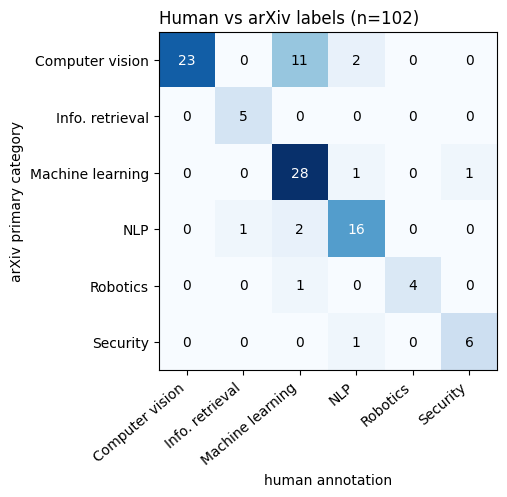

In [19]:
if RUN_LLM and RUN_ANNOTATION and len(llm_sample):
    from statsmodels.stats.inter_rater import fleiss_kappa, aggregate_raters
    RATERS = build_raters()
    RATERS['Gemini'] = llm_sample.llm_label
    pairs = HUMAN_PAIRS + [('Gemini', 'arXiv label'), ('Gemini', 'You (all)'), ('Gemini', 'You (blind)'), ('Gemini', 'Helper (blind)')]
    agree_all = agreement_table(RATERS, pairs)
    save_table(agree_all, 'agreement_all_raters')
    display(agree_all)

    fl_rows = []
    for group in [['arXiv label', 'You (all)', 'Gemini'], ['arXiv label', 'You (blind)', 'Helper (blind)', 'Gemini']]:
        if not all(g in RATERS for g in group):
            continue
        common = set.intersection(*[set(RATERS[g].dropna().index) for g in group])
        if len(common) < 5:
            continue
        common = sorted(common)
        M = np.array([[CLASSES.index(RATERS[g][i]) for g in group] for i in common])
        table, _ = aggregate_raters(M, n_cat=len(CLASSES))
        fk = fleiss_kappa(table)
        fl_rows.append({'Raters': ' + '.join(group), 'Papers': len(common), "Fleiss' kappa": round(fk, 3), 'Reading': landis_koch(fk)})
    if fl_rows:
        fleiss_tab = pd.DataFrame(fl_rows)
        save_table(fleiss_tab, 'agreement_fleiss')
        display(fleiss_tab)

    conf = (llm_sample.assign(correct=llm_sample.llm_label == llm_sample.arxiv_label)
            .groupby('llm_conf').correct.agg(['mean', 'size']).rename(columns={'mean': 'agrees with arXiv', 'size': 'papers'}))
    display(conf.round(2))

    you = RATERS['You (all)']
    if len(you):
        common = you.index.intersection(RATERS['arXiv label'].index)
        cm = confusion_matrix(RATERS['arXiv label'][common], you[common], labels=CLASSES)
        fig, ax = plt.subplots(figsize=(5.2, 4.4))
        ax.imshow(cm, cmap='Blues')
        for i in range(len(CLASSES)):
            for j in range(len(CLASSES)):
                ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
        ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=40, ha='right')
        ax.set_yticks(range(len(CLASSES)), CLASSES)
        ax.set_xlabel('human annotation')
        ax.set_ylabel('arXiv primary category')
        ax.set_title(f'Human vs arXiv labels (n={len(common)})', loc='left')
        save_fig(fig, 'annotation_confusion')

---
## 6. The arXiv graph: wider testing
### 6.1 Methods and the training loop
* **MLP** uses only the text features (no edges) – shows how much the citation graph adds. **Mixup+MLP** is the original input Mixup (Zhang et al., 2018): features and labels of random training pairs are mixed.
* **GCN / JKNet / GraphConv** use the shared two-stage Mixup model; **GraphConv** is the layer of the authors' released code (mean aggregation + root weight, identical to full-batch GraphSAGE-mean), so a separate GraphSAGE entry would be the same model. **GAT** is the attention baseline (no Mixup version exists in the paper).
* `a4` = λ ~ Beta(4, 4) as in the released code; otherwise α = 1 as in the paper.

The loop is the reproduction's `train_transductive` with three additions: macro-F1 and per-class F1 at the selected epoch, an optional smaller training set (label-rate study), and optional per-epoch history / extra epoch caps (Section 8).

In [20]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden, out_dim, num_layers, dropout):
        super().__init__()
        self.lins = nn.ModuleList([nn.Linear(in_dim if l == 0 else hidden, hidden) for l in range(num_layers)])
        self.cls, self.dropout = nn.Linear(hidden, out_dim), dropout

    def forward(self, x, G=None):
        for lin in self.lins:
            x = F.dropout(F.relu(lin(x)), self.dropout, self.training)
        return self.cls(x)

    def forward_mixup(self, x, G, lam, perm):                   # input Mixup (Zhang et al., 2018)
        return self.forward(lam * x + (1 - lam) * x[perm])


SPECS = {
    'MLP':                dict(arch='mlp', mixup=False),
    'Mixup+MLP':          dict(arch='mlp', mixup=True),
    'GCN':                dict(arch='mix', kind='gcn', jk=None, mixup=False),
    'Mixup+GCN':          dict(arch='mix', kind='gcn', jk=None, mixup=True),
    'Mixup+GCN a4':       dict(arch='mix', kind='gcn', jk=None, mixup=True, alpha=4.0),
    'DropEdge+GCN':       dict(arch='mix', kind='gcn', jk=None, mixup=False, dropedge=True),
    'JKNet':              dict(arch='mix', kind='gcn', jk='cat', mixup=False),
    'Mixup+JKNet':        dict(arch='mix', kind='gcn', jk='cat', mixup=True),
    'GraphConv':          dict(arch='mix', kind='graphconv', jk=None, mixup=False),
    'Mixup+GraphConv':    dict(arch='mix', kind='graphconv', jk=None, mixup=True),
    'Mixup+GraphConv a4': dict(arch='mix', kind='graphconv', jk=None, mixup=True, alpha=4.0),
    'GAT':                dict(arch='gat', fixed_depth=2),
}


def graph_of(D, kind):
    if kind not in D.graphs:
        D.graphs[kind] = make_graph(D.rowptr, D.col, D.n, kind, DEVICE)
    return D.graphs[kind]


def train_node(D, split, method, depth, seed, hp=None, train_idx=None, caps=(), history=False, return_pred=False):
    spec = SPECS[method]
    set_seed(seed)
    x, y = D.x.to(DEVICE), D.y.to(DEVICE)
    tr = (train_idx if train_idx is not None else split['train']).to(DEVICE)
    va, te = split['val'].to(DEVICE), split['test'].to(DEVICE)
    if spec['arch'] == 'gat':
        hp = hp or GAT_HP
        model = GATNet(D.num_features, D.num_classes, hp['hidden'], hp['heads'], hp['dropout']).to(DEVICE)
        ei = D.edge_index.to(DEVICE)
        fwd = lambda G: model(x, ei)
        G_full = None
    else:
        hp = hp or HP
        if spec['arch'] == 'mlp':
            model, G_full = MLP(D.num_features, hp['hidden'], D.num_classes, depth, hp['dropout']).to(DEVICE), None
        else:
            model = TwoStageMixupGNN(D.num_features, hp['hidden'], D.num_classes, depth,
                                     spec['kind'], spec['jk'], hp['dropout']).to(DEVICE)
            G_full = graph_of(D, spec['kind'])
        fwd = lambda G: model(x, G)
    opt = torch.optim.Adam(model.parameters(), lr=hp['lr'], weight_decay=hp['weight_decay'])
    alpha = spec.get('alpha', MIXUP_ALPHA)

    blank = lambda: dict(val=-1.0, val_loss=float('inf'), test=0.0, epoch=0, pred=None)
    best, best_cap, hist = blank(), {c: blank() for c in caps}, []
    t0 = time.time()
    for epoch in range(1, hp['epochs'] + 1):
        model.train()
        opt.zero_grad()
        G = G_full
        if spec.get('dropedge'):
            rp, cl = edge_index_to_csr(drop_edge_undirected(D.edge_index, DROPEDGE_P), D.n)
            G = make_graph(rp, cl, D.n, spec['kind'], DEVICE)
        if spec.get('mixup'):
            lam = float(np.random.beta(alpha, alpha))
            perm = torch.arange(D.n, device=DEVICE)
            perm[tr] = tr[torch.randperm(tr.numel(), device=DEVICE)]
            out = model.forward_mixup(x, G, lam, perm)
            loss = lam * F.cross_entropy(out[tr], y[tr]) + (1 - lam) * F.cross_entropy(out[tr], y[perm[tr]])
        else:
            out = fwd(G)
            loss = F.cross_entropy(out[tr], y[tr])
        loss.backward()
        opt.step()

        model.eval()
        with torch.no_grad():
            out = fwd(G_full)
            pred = out.argmax(1)
            val_acc = (pred[va] == y[va]).float().mean().item()
            test_acc = (pred[te] == y[te]).float().mean().item()
            val_loss = F.cross_entropy(out[va], y[va]).item()
        if history:
            hist.append((epoch, loss.item(), val_acc, test_acc, val_loss))
        for b, cap in [(best, None)] + [(best_cap[c], c) for c in caps]:
            if cap is not None and epoch > cap:
                continue
            if val_acc > b['val'] or (val_acc == b['val'] and val_loss < b['val_loss']):
                b.update(val=val_acc, val_loss=val_loss, test=test_acc, epoch=epoch, pred=pred.cpu())

    y_te, p_te = D.y[split['test']].numpy(), best['pred'][split['test']].numpy()
    rec = dict(val=100 * best['val'], test=100 * best['test'], test_last=100 * test_acc, best_epoch=best['epoch'],
               f1_macro=100 * f1_score(y_te, p_te, average='macro', labels=range(D.num_classes), zero_division=0),
               f1_class=[round(100 * v, 2) for v in f1_score(y_te, p_te, average=None, labels=range(D.num_classes), zero_division=0)],
               secs=round(time.time() - t0, 2))
    for c, b in best_cap.items():
        rec[f'test@{c}'], rec[f'best_epoch@{c}'] = 100 * b['test'], b['epoch']
    if history:
        rec['history'] = hist
    if return_pred:
        rec['pred'] = best['pred'].numpy()
    return rec

print('training loop ready')

training loop ready


### 6.2 Runner and summaries
Seed = `100 * split + trial`, as in the reproduction, so a method and its Mixup version always see the same split and the same seed – which is what makes the paired tests below valid.

In [21]:
def run_grid(tag, datasets, methods, depths, n_splits, n_seeds, hp=None, train_rate=None, caps=()):
    jobs = []
    for name in datasets:
        for m in methods:
            for L in ([SPECS[m]['fixed_depth']] if 'fixed_depth' in SPECS[m] else depths):
                for s in range(n_splits):
                    for t in range(n_seeds):
                        k = f'{tag}|{name}|{m}|L{L}|s{s}|t{t}'
                        if k not in STORE:
                            jobs.append((k, name, m, L, s, t))
    print(f'{tag}: {len(jobs)} runs to do')
    for k, name, m, L, s, t in tqdm(jobs, desc=tag):
        D = load_dataset(name)
        sp = make_split(D.n, s)
        tri = sp['train'][: int(train_rate * D.n)] if train_rate else None
        h = (GAT_HP if SPECS[m]['arch'] == 'gat' else hp) if hp else None
        rec = train_node(D, sp, m, L, seed=100 * s + t, hp=h, train_idx=tri, caps=caps)
        STORE.put(k, dict(rec, tag=tag, dataset=name, method=m, depth=L, split=s, trial=t))


def summarise(prefix):
    """Mean ± std per (dataset, method); depth chosen by mean validation accuracy, as in the paper."""
    df = STORE.frame(prefix)
    if df.empty:
        return df, df, df
    g = (df.groupby(['dataset', 'method', 'depth'])
           .agg(val=('val', 'mean'), acc=('test', 'mean'), acc_std=('test', 'std'),
                f1=('f1_macro', 'mean'), f1_std=('f1_macro', 'std'), runs=('test', 'size'))
           .reset_index().fillna({'acc_std': 0, 'f1_std': 0}))
    best = g.loc[g.groupby(['dataset', 'method'])['val'].idxmax()].reset_index(drop=True)
    return best, g, df


def runs_of(df, best, dataset, method, metric):
    L = int(best[(best.dataset == dataset) & (best.method == method)].depth.iloc[0])
    return df[(df.dataset == dataset) & (df.method == method) & (df.depth == L)].set_index(['split', 'trial'])[metric]


def paired_gains(df, best, datasets, pairs, metric='test'):
    """Mixup − backbone over identical (split, seed) pairs: mean gain, 95% CI, wins, paired t-test and Wilcoxon."""
    rows = []
    for d in datasets:
        have = set(best[best.dataset == d].method)
        for base, mix in pairs:
            if not {base, mix} <= have:
                continue
            b, m = runs_of(df, best, d, base, metric), runs_of(df, best, d, mix, metric)
            idx = b.index.intersection(m.index)
            diff = (m[idx] - b[idx]).values
            n = len(diff)
            half = stats.t.ppf(0.975, n - 1) * diff.std(ddof=1) / math.sqrt(n) if n > 1 else np.nan
            p_t = stats.ttest_rel(m[idx], b[idx]).pvalue if n > 1 and diff.std() > 0 else np.nan
            p_w = stats.wilcoxon(diff).pvalue if n > 5 and (diff != 0).any() else np.nan
            rows.append({'Dataset': d, 'Comparison': f'{mix} − {base}', 'Metric': metric, 'Backbone': round(b[idx].mean(), 2),
                         'Mixup': round(m[idx].mean(), 2), 'Gain': round(diff.mean(), 2),
                         '95% CI': f'[{diff.mean() - half:+.2f}, {diff.mean() + half:+.2f}]',
                         'Mixup wins': f'{int((diff > 0).sum())}/{n}', 'p (paired t)': round(p_t, 4), 'p (Wilcoxon)': round(p_w, 4)})
    return pd.DataFrame(rows)


def fmt(m, s):
    return f'{m:.1f} ± {s:.1f}'

print('runner ready')

runner ready


### 6.3 Run (≈ 30 min on a T4 with the default 10 splits × 3 seeds × 2 depths)

In [22]:
if RUN_ARXIV_TESTS:
    run_grid('AX', ['arXiv'], AX_METHODS, AX_DEPTHS, AX_SPLITS, AX_SEEDS)

AX: 0 runs to do


AX: 0it [00:00, ?it/s]

### 6.4 Results: accuracy and macro-F1
Macro-F1 averages the F1 of the six classes equally, so it shows whether a method also works on the small classes (Info. retrieval is only 3 % of the papers), which accuracy hides.

In [23]:
best_ax, all_ax, df_ax = summarise('AX|')
if not best_ax.empty:
    order = [m for m in AX_METHODS if m in set(best_ax.method)]
    res_ax = best_ax.set_index('method').loc[order]
    table_ax = pd.DataFrame({'Method': order, 'Depth': res_ax.depth.values,
                             'Accuracy (%)': [fmt(a, s) for a, s in zip(res_ax.acc, res_ax.acc_std)],
                             'Macro-F1 (%)': [fmt(a, s) for a, s in zip(res_ax.f1, res_ax.f1_std)],
                             'Runs': res_ax.runs.values})
    save_table(table_ax, 'arxiv_results')
    display(table_ax)
    display(all_ax.pivot_table(index='method', columns='depth', values='acc').loc[order].round(1))

,Method,Depth,Accuracy (%),Macro-F1 (%),Runs
0,MLP,2,83.8 ± 1.4,78.2 ± 3.5,30
1,Mixup+MLP,2,84.2 ± 1.1,80.0 ± 3.2,30
2,GCN,2,82.9 ± 1.5,78.7 ± 2.9,30
3,Mixup+GCN,2,82.6 ± 1.3,78.1 ± 2.6,30
4,DropEdge+GCN,2,83.0 ± 1.6,78.7 ± 2.9,30
5,JKNet,2,83.4 ± 1.4,79.3 ± 2.7,30
6,Mixup+JKNet,2,83.4 ± 1.2,79.6 ± 3.0,30
7,GraphConv,2,85.4 ± 1.1,81.3 ± 2.9,30
8,Mixup+GraphConv,2,85.4 ± 1.1,81.7 ± 2.3,30
9,Mixup+GraphConv a4,2,85.3 ± 0.9,81.6 ± 1.7,30


depth,2,3
method,,
MLP,83.8,83.3
Mixup+MLP,84.2,83.8
GCN,82.9,81.8
Mixup+GCN,82.6,81.8
DropEdge+GCN,83.0,82.1
JKNet,83.4,82.8
Mixup+JKNet,83.4,83.0
GraphConv,85.4,85.2
Mixup+GraphConv,85.4,85.0


### 6.5 Does Mixup improve its backbone on the new graph?

In [24]:
PAIRS = [('MLP', 'Mixup+MLP'), ('GCN', 'Mixup+GCN'), ('JKNet', 'Mixup+JKNet'),
         ('GraphConv', 'Mixup+GraphConv'), ('GraphConv', 'Mixup+GraphConv a4'), ('DropEdge+GCN', 'Mixup+GCN')]
if not best_ax.empty:
    gains_ax = pd.concat([paired_gains(df_ax, best_ax, ['arXiv'], PAIRS, 'test'),
                          paired_gains(df_ax, best_ax, ['arXiv'], PAIRS, 'f1_macro')])
    save_table(gains_ax, 'arxiv_mixup_gains')
    display(gains_ax)

,Dataset,Comparison,Metric,Backbone,Mixup,Gain,95% CI,Mixup wins,p (paired t),p (Wilcoxon)
0,arXiv,Mixup+MLP − MLP,test,83.85,84.17,0.33,"[-0.06, +0.71]",16/30,0.0954,0.0970
1,arXiv,Mixup+GCN − GCN,test,82.87,82.63,-0.24,"[-0.50, +0.02]",9/30,0.0659,0.0434
2,arXiv,Mixup+JKNet − JKNet,test,83.42,83.38,-0.04,"[-0.31, +0.24]",14/30,0.7915,1.0000
3,arXiv,Mixup+GraphConv − GraphConv,test,85.44,85.42,-0.02,"[-0.40, +0.36]",10/30,0.9242,0.6566
4,arXiv,Mixup+GraphConv a4 − GraphConv,test,85.44,85.28,-0.15,"[-0.57, +0.27]",10/30,0.4592,0.3945
5,arXiv,Mixup+GCN − DropEdge+GCN,test,83.02,82.63,-0.39,"[-0.69, -0.09]",8/30,0.0122,0.0136
0,arXiv,Mixup+MLP − MLP,f1_macro,78.16,79.97,1.81,"[+1.16, +2.46]",26/30,0.0000,0.0000
1,arXiv,Mixup+GCN − GCN,f1_macro,78.65,78.12,-0.54,"[-0.99, -0.08]",11/30,0.0231,0.0345
2,arXiv,Mixup+JKNet − JKNet,f1_macro,79.29,79.58,0.29,"[-0.23, +0.81]",19/30,0.2594,0.1772
3,arXiv,Mixup+GraphConv − GraphConv,f1_macro,81.27,81.67,0.40,"[-0.29, +1.09]",15/30,0.2497,0.3931


### 6.6 Per-class F1: where does Mixup help or hurt?

,Computer vision,Info. retrieval,Machine learning,NLP,Robotics,Security
MLP,89.3,65.5,79.1,89.8,74.9,70.5
Mixup+MLP,89.5,72.5,78.6,89.9,77.8,71.5
GCN,88.5,73.4,77.1,88.9,76.7,67.3
Mixup+GCN,88.2,70.4,76.8,88.8,76.9,67.7
DropEdge+GCN,88.6,73.7,77.2,89.2,76.7,66.9
JKNet,88.8,75.3,77.9,89.6,76.2,68.1
Mixup+JKNet,88.7,74.4,77.5,89.0,79.0,68.8
GraphConv,90.8,78.2,80.6,91.0,77.4,69.7
Mixup+GraphConv,90.8,77.5,80.1,90.7,79.3,71.5
Mixup+GraphConv a4,90.7,77.9,80.0,90.4,79.7,71.1


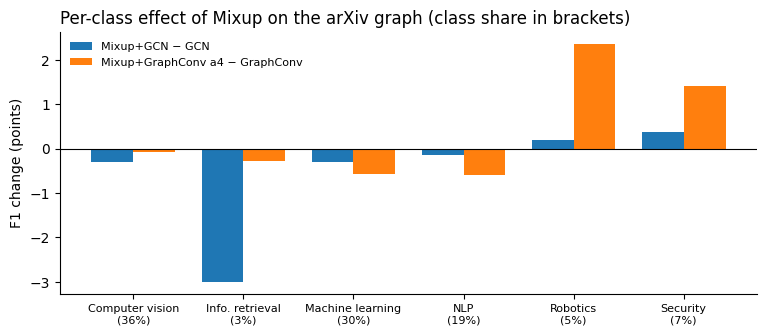

In [25]:
if not best_ax.empty:
    share = papers.label.value_counts(normalize=True)
    pc = {}
    for m in order:
        runs = runs_of(df_ax, best_ax, 'arXiv', m, 'f1_class')
        pc[m] = np.mean(np.stack(runs.values), 0)
    per_class = pd.DataFrame(pc, index=CLASSES).T.round(1)
    per_class.loc['class share (%)'] = [round(100 * share[c], 1) for c in CLASSES]
    save_table(per_class.reset_index(names='method'), 'arxiv_per_class_f1')
    display(per_class)
    fig, ax = plt.subplots(figsize=(9, 3.4))
    w = 0.38
    xs = np.arange(len(CLASSES))
    for k, (base, mix) in enumerate([('GCN', 'Mixup+GCN'), ('GraphConv', 'Mixup+GraphConv a4')]):
        if base in pc and mix in pc:
            ax.bar(xs + (k - 0.5) * w, pc[mix] - pc[base], w, label=f'{mix} − {base}')
    ax.axhline(0, color='black', lw=0.8)
    ax.set_xticks(xs, [f'{c}\n({100 * share[c]:.0f}%)' for c in CLASSES], fontsize=8)
    ax.set_ylabel('F1 change (points)')
    ax.set_title('Per-class effect of Mixup on the arXiv graph (class share in brackets)', loc='left')
    ax.legend(frameon=False, fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
    save_fig(fig, 'arxiv_per_class_gain')

### 6.7 Label-rate study: does Mixup help when labels are scarce?
Mixup is a regulariser, so if it helps anywhere it should be with few training labels. The validation and test sets stay fixed (the same 20 % / 20 % as above); only the training set is cut to 5–60 % of all nodes. Depth is fixed at `LR_DEPTH`.

LR0.05: 0 runs to do


LR0.05: 0it [00:00, ?it/s]

LR0.1: 0 runs to do


LR0.1: 0it [00:00, ?it/s]

LR0.2: 0 runs to do


LR0.2: 0it [00:00, ?it/s]

... (2 outputs left out)

LR0.6: 0 runs to do


LR0.6: 0it [00:00, ?it/s]

,5% labels,10% labels,20% labels,30% labels,60% labels
method,,,,,
MLP,78.2,80.1,81.5,83.0,83.8
GCN,77.3,80.3,81.7,82.5,82.8
Mixup+GCN,77.3,80.2,81.8,82.3,82.7
GraphConv,79.4,82.0,83.3,84.5,85.5
Mixup+GraphConv a4,79.3,81.9,83.3,84.3,85.3


,Train labels,Comparison,Backbone,Mixup,Gain,95% CI,Mixup wins,p (paired t)
0,5%,Mixup+GCN − GCN,77.29,77.27,-0.02,"[-0.49, +0.45]",10/20,0.9375
1,5%,Mixup+GraphConv a4 − GraphConv,79.37,79.26,-0.11,"[-0.88, +0.67]",10/20,0.7764
2,5%,GCN − MLP,78.21,77.29,-0.91,"[-1.63, -0.19]",6/20,0.0155
0,10%,Mixup+GCN − GCN,80.27,80.20,-0.07,"[-0.56, +0.42]",10/20,0.7646
1,10%,Mixup+GraphConv a4 − GraphConv,82.01,81.94,-0.07,"[-0.43, +0.29]",8/20,0.6860
2,10%,GCN − MLP,80.12,80.27,0.15,"[-0.74, +1.04]",10/20,0.7257
0,20%,Mixup+GCN − GCN,81.74,81.77,0.03,"[-0.25, +0.30]",9/20,0.8424
1,20%,Mixup+GraphConv a4 − GraphConv,83.26,83.30,0.04,"[-0.40, +0.48]",8/20,0.8349
2,20%,GCN − MLP,81.51,81.74,0.23,"[-0.77, +1.23]",10/20,0.6353
0,30%,Mixup+GCN − GCN,82.48,82.33,-0.15,"[-0.43, +0.13]",7/20,0.2742


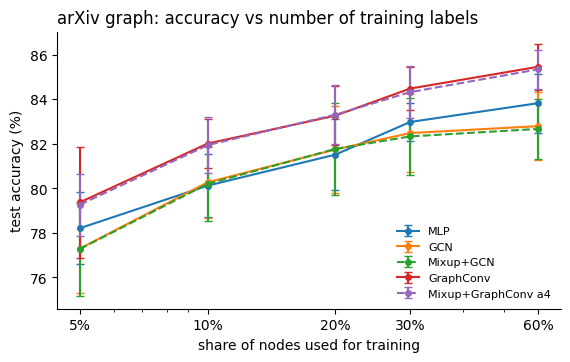

In [26]:
if RUN_LABEL_RATE:
    for r in LABEL_RATES:
        run_grid(f'LR{r:g}', ['arXiv'], LR_METHODS, [LR_DEPTH], LR_SPLITS, LR_SEEDS, train_rate=r)
lr_rows, lr_gain = [], []
for r in LABEL_RATES:
    b, _, d = summarise(f'LR{r:g}|')
    if b.empty:
        continue
    lr_rows.append(b.assign(rate=r))
    gg = paired_gains(d, b, ['arXiv'], [('GCN', 'Mixup+GCN'), ('GraphConv', 'Mixup+GraphConv a4'), ('MLP', 'GCN')], 'test')
    lr_gain.append(gg.assign(**{'Train labels': f'{int(100 * r)}%'}))
if lr_rows:
    lr = pd.concat(lr_rows)
    lr_table = lr.pivot_table(index='method', columns='rate', values='acc').loc[[m for m in LR_METHODS if m in set(lr.method)]].round(1)
    lr_table.columns = [f'{int(100 * c)}% labels' for c in lr_table.columns]
    save_table(lr_table.reset_index(), 'arxiv_label_rate')
    display(lr_table)
    lr_gain = pd.concat(lr_gain)
    save_table(lr_gain, 'arxiv_label_rate_gains')
    display(lr_gain[['Train labels', 'Comparison', 'Backbone', 'Mixup', 'Gain', '95% CI', 'Mixup wins', 'p (paired t)']])
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    for m in lr_table.index:
        s = lr[lr.method == m].sort_values('rate')
        ax.errorbar(100 * s.rate, s.acc, yerr=s.acc_std, marker='o', ms=4, capsize=3, label=m,
                    ls='--' if m.startswith('Mixup') else '-')
    ax.set_xscale('log')
    ax.set_xticks([100 * r for r in LABEL_RATES], [f'{int(100 * r)}%' for r in LABEL_RATES])
    ax.set_xlabel('share of nodes used for training')
    ax.set_ylabel('test accuracy (%)')
    ax.set_title('arXiv graph: accuracy vs number of training labels', loc='left')
    ax.legend(frameon=False, fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)
    save_fig(fig, 'arxiv_label_rate')

---
## 7. What are the model's mistakes? (LLM-as-a-judge, part 2)
### 7.1 Predictions of the best model on one split
The method with the best validation accuracy in Section 6 is re-trained on split `JUDGE_SPLIT` and its test-set mistakes are collected with useful context: is the paper cross-listed on arXiv, and what share of its neighbours carry its own label (**local homophily**)?

In [27]:
if RUN_ERROR_STUDY:
    if JUDGE_METHOD is None:
        cand = best_ax[best_ax.dataset == 'arXiv'] if not best_ax.empty else pd.DataFrame()
        JUDGE_METHOD, JUDGE_DEPTH = ((cand.loc[cand.val.idxmax(), 'method'], int(cand.loc[cand.val.idxmax(), 'depth']))
                                     if len(cand) else ('GraphConv', 2))
    else:
        JUDGE_DEPTH = int(best_ax[(best_ax.dataset == 'arXiv') & (best_ax.method == JUDGE_METHOD)].depth.iloc[0]) if not best_ax.empty else 2
    sp = make_split(ARXIV.n, JUDGE_SPLIT)
    te = sp['test'].numpy()
    PRED_PATH = osp.join(OUT, f'judge_predictions{"_quick" if QUICK else ""}.json')
    saved_pred = json.load(open(PRED_PATH)) if osp.exists(PRED_PATH) else {}
    if saved_pred.get('method') == JUDGE_METHOD and saved_pred.get('split') == JUDGE_SPLIT:
        judge_run = dict(test=saved_pred['test'], pred=np.array(saved_pred['pred']))      # same mistakes as before
        print('using the saved predictions from the first run (so Gemini is asked about the same papers)')
    else:
        judge_run = train_node(ARXIV, sp, JUDGE_METHOD, JUDGE_DEPTH, seed=100 * JUDGE_SPLIT, return_pred=True)
        json.dump(dict(method=JUDGE_METHOD, depth=JUDGE_DEPTH, split=JUDGE_SPLIT, test=judge_run['test'],
                       pred=judge_run['pred'].tolist()), open(PRED_PATH, 'w'))
    rows = csr_rows(ARXIV.rowptr).numpy()
    same = (ARXIV.y[ARXIV.col].numpy() == ARXIV.y[rows].numpy())
    local_h = np.bincount(rows, weights=same, minlength=ARXIV.n) / np.maximum(np.bincount(rows, minlength=ARXIV.n), 1)
    ev = papers.iloc[te][['node', 'arxiv_id', 'title', 'label', 'abstract']].copy()
    ev['pred'] = [CLASSES[i] for i in judge_run['pred'][te]]
    ev['correct'] = ev.pred == ev.label
    ev['cross_listed'] = papers.iloc[te].get('cross_listed', pd.Series(0, index=ev.index)).fillna(0).astype(float).values > 0
    ev['degree'] = ARXIV.rowptr.diff().numpy()[te]
    ev['local_homophily'] = local_h[te]
    errors = ev[~ev.correct]
    print(f'{JUDGE_METHOD} (L={JUDGE_DEPTH}) on split {JUDGE_SPLIT}: test accuracy {judge_run["test"]:.2f}%, '
          f'{len(errors)} mistakes out of {len(ev)} test papers')
    cm = confusion_matrix(ev.label, ev.pred, labels=CLASSES)
    display(pd.DataFrame(cm, index=[f'true {c}' for c in CLASSES], columns=[f'pred {c}' for c in CLASSES]))

Mixup+GraphConv (L=2) on split 0: test accuracy 84.72%, 86 mistakes out of 563 test papers


,pred Computer vision,pred Info. retrieval,pred Machine learning,pred NLP,pred Robotics,pred Security
true Computer vision,189,0,12,2,4,4
true Info. retrieval,0,9,1,3,0,0
true Machine learning,14,0,122,8,5,14
true NLP,2,3,4,105,0,0
true Robotics,4,0,1,0,25,0
true Security,1,0,4,0,0,27


### 7.2 Where do the mistakes happen? (no LLM needed)
If mistakes concentrate on papers whose neighbours mostly have *other* labels, the graph itself is pulling the prediction away – this is also exactly where neighbourhood-based Mixup has the least reliable signal.

In [28]:
if RUN_ERROR_STUDY:
    ev['homophily band'] = pd.cut(ev.local_homophily, [-0.01, 0.25, 0.5, 0.75, 1.0],
                                  labels=['0–25%', '25–50%', '50–75%', '75–100%'])
    by_h = ev.groupby('homophily band', observed=False).correct.agg(['size', 'mean']).rename(
        columns={'size': 'test papers', 'mean': 'accuracy'})
    by_h['accuracy'] = (100 * by_h.accuracy).round(1)
    by_x = ev.groupby('cross_listed').correct.agg(['size', 'mean']).rename(columns={'size': 'test papers', 'mean': 'accuracy'})
    by_x['accuracy'] = (100 * by_x.accuracy).round(1)
    by_x.index = ['single category', 'cross-listed'][: len(by_x)] if len(by_x) == 2 else by_x.index
    display(by_h)
    display(by_x)
    save_table(by_h.reset_index(), 'errors_by_local_homophily')
    save_table(by_x.reset_index(names='arXiv listing'), 'errors_by_cross_listing')

,test papers,accuracy
homophily band,,
0–25%,58,43.1
25–50%,106,71.7
50–75%,139,87.1
75–100%,260,98.1


,test papers,accuracy
single category,211,91.9
cross-listed,352,80.4


In [45]:
   # The judge (7.3) uses gemini-3-flash-preview: the free-tier daily limit for gemini-3.8-flash
   # (used for the annotation in Section 5) was reached on 3 Nov 2026, and gemini-3.7-flash shares
   # that limit. All judging (mistakes and control) uses this one model.
   GEMINI_MODEL = 'gemini-3-flash-preview'
   LLM_STOPPED = False

### 7.3 Gemini judges each mistake
For each mistake Gemini sees the title and abstract and two candidate areas: the arXiv label and the model's prediction, in **random order** and **without being told which is which** (to avoid position and authority bias). It answers A, B, *both* (genuinely interdisciplinary) or *neither*.

**Control set:** correctly classified papers paired with a random wrong area. A trustworthy judge should almost always pick the arXiv label there; if it does, its verdicts on the real mistakes can be believed.

In [48]:
JUDGE_SCHEMA = {'type': 'ARRAY', 'items': {'type': 'OBJECT', 'properties': {
    'item': {'type': 'INTEGER'},
    'verdict': {'type': 'STRING', 'enum': ['A', 'B', 'both', 'neither']},
    'reason': {'type': 'STRING'}}, 'required': ['item', 'verdict', 'reason']}}


def judge_prompt(batch):
    txt = '\n\n'.join(f'[item {i}]\nTitle: {t}\nAbstract: {a}\nLabel A: {la}\nLabel B: {lb}' for i, t, a, la, lb in batch)
    return ('You are an expert reviewer of computer-science research. For each paper below, two candidate research-area '
            'labels are given (A and B). The six possible areas are:\n' + GUIDE_TEXT +
            '\n\nDecide which label better describes the MAIN contribution of the paper. Answer "A" or "B" if one fits '
            'clearly better, "both" if the paper genuinely belongs to both areas about equally, and "neither" if neither '
            'fits. Give a reason of at most 20 words.\nReturn a JSON list with one object per paper: item, verdict, reason.'
            f'\n\nPapers:\n\n{txt}')


def run_judge(df, wrong_col, task):
    rng = np.random.RandomState(7)
    df = df.copy()
    df['arxiv_is_A'] = rng.rand(len(df)) < 0.5
    out = []
    recs = list(df.itertuples())
    for i in tqdm(range(0, len(recs), JUDGE_BATCH), desc=f'Gemini {task}'):
        b = recs[i:i + JUDGE_BATCH]
        items = [(j + 1, r.title, (r.abstract or paper_text(r.arxiv_id))[:1500],
                  r.label if r.arxiv_is_A else getattr(r, wrong_col),
                  getattr(r, wrong_col) if r.arxiv_is_A else r.label) for j, r in enumerate(b)]
        ans = ask_gemini(task, ','.join(r.arxiv_id for r in b), judge_prompt(items), JUDGE_SCHEMA) or []
        got = {int(a['item']): a for a in ans if isinstance(a, dict) and 'item' in a}
        for j, r in enumerate(b):
            a = got.get(j + 1)
            if a is None:
                continue
            v = a['verdict']
            pick = {'both': 'both', 'neither': 'neither'}.get(v, 'arXiv label' if (v == 'A') == r.arxiv_is_A else 'other label')
            out.append(dict(arxiv_id=r.arxiv_id, verdict=pick, reason=a.get('reason', '')))
    return df.merge(pd.DataFrame(out, columns=['arxiv_id', 'verdict', 'reason']), on='arxiv_id', how='left')


if RUN_ERROR_STUDY and RUN_LLM:
    err_s = errors.sample(min(JUDGE_MAX_ERRORS, len(errors)), random_state=0)
    judged_err = run_judge(err_s, 'pred', 'judge_errors')
    ctrl = ev[ev.correct].sample(min(CONTROL_N, int(ev.correct.sum())), random_state=0).copy()
    crng = np.random.RandomState(11)
    ctrl['decoy'] = [crng.choice([c for c in CLASSES if c != l]) for l in ctrl.label]
    judged_ctrl = run_judge(ctrl, 'decoy', 'judge_control')
    judged_err.drop(columns=['abstract']).to_csv(osp.join(TAB, 'gemini_judge_errors.csv'), index=False)
    judged_ctrl.drop(columns=['abstract']).to_csv(osp.join(TAB, 'gemini_judge_control.csv'), index=False)

Gemini judge_errors:   0%|          | 0/2 [00:00<?, ?it/s]

Gemini judge_control:   0%|          | 0/1 [00:00<?, ?it/s]

### 7.4 Judge results
* **Control:** how often Gemini prefers the true arXiv label over a random wrong one (should be close to 100 %).
* **Mistakes:** "other label" = Gemini thinks the *model's* prediction fits better; "both" = the paper sits across two areas. Together these are the mistakes that are better described as **label ambiguity** than model failure.

In [49]:
if RUN_ERROR_STUDY and RUN_LLM and 'judged_err' in globals() and judged_err.verdict.notna().any():
    names = {'arXiv label': 'arXiv label fits better', 'other label': 'model/decoy label fits better',
             'both': 'both fit', 'neither': 'neither fits'}
    summ = pd.DataFrame({
        f'Model mistakes (n={judged_err.verdict.notna().sum()})': judged_err.verdict.value_counts(normalize=True),
        f'Control: random wrong label (n={judged_ctrl.verdict.notna().sum()})': judged_ctrl.verdict.value_counts(normalize=True),
    }).reindex(list(names)).fillna(0).mul(100).round(1)
    summ.index = [names[i] for i in summ.index]
    save_table(summ.reset_index(names='Gemini verdict (%)'), 'gemini_judge_summary')
    display(summ)
    je = judged_err[judged_err.verdict.notna()]                    # only mistakes Gemini actually answered
    amb = je.verdict.isin(['other label', 'both']).mean()
    print(f'{100 * amb:.0f}% of the {len(je)} judged mistakes are plausible labels (model label better, or both fit).'
          + (f'  NOTE: only {len(je)} of {len(judged_err)} mistakes have a verdict yet - re-run after the quota resets.' if len(je) < len(judged_err) else ''))
    acc = judge_run['test']
    print(f'Upper estimate: if ambiguous mistakes were not counted as errors, accuracy on split {JUDGE_SPLIT} would be '
          f'about {acc + (100 - acc) * amb:.1f}% instead of {acc:.1f}% (from the {len(je)} judged mistakes).')
    by_cls = (je.assign(plausible=je.verdict.isin(['other label', 'both']))
              .groupby('label').plausible.agg(['size', 'mean']).rename(columns={'size': 'mistakes judged', 'mean': 'plausible share'}))
    display(by_cls.round(2))
    ex = je[je.verdict.isin(['other label', 'both'])].head(6)[['arxiv_id', 'title', 'label', 'pred', 'verdict', 'reason']]
    save_table(ex, 'gemini_judge_examples')
    display(ex)

,Model mistakes (n=86),Control: random wrong label (n=40)
arXiv label fits better,33.7,92.5
model/decoy label fits better,37.2,0.0
both fit,24.4,7.5
neither fits,4.7,0.0


62% of the 86 judged mistakes are plausible labels (model label better, or both fit).
Upper estimate: if ambiguous mistakes were not counted as errors, accuracy on split 0 would be about 94.1% instead of 84.7% (from the 86 judged mistakes).


,mistakes judged,plausible share
label,,
Computer vision,22,0.64
Info. retrieval,4,1.00
Machine learning,41,0.66
NLP,9,0.56
Robotics,5,0.20
Security,5,0.40


,arxiv_id,title,label,pred,verdict,reason
0,2004.05703,DarkneTZ: Towards Model Privacy at the Edge using Trusted Execution Environments,Machine learning,Security,other label,The main contribution is a security framework using TEEs to protect model privacy against membership inference attacks.
1,1909.06122,FakeSpotter: A Simple yet Robust Baseline for Spotting AI-Synthesized Fake Faces,Security,Computer vision,both,It addresses a computer vision task (face detection) as a security defense against AI-synthesized misinformation.
2,1704.03073,Data-efficient Deep Reinforcement Learning for Dexterous Manipulation,Machine learning,Robotics,other label,The primary application and motivation are solving complex robotic manipulation tasks like grasping and stacking.
4,1505.00468,VQA: Visual Question Answering,NLP,Computer vision,both,VQA is a classic multimodal task sitting at the intersection of computer vision and natural language processing.
8,2103.12857,Embracing the Disharmony in Medical Imaging: A Simple and Effective Framework for Domain Adaptation,Machine learning,Computer vision,both,Develops machine learning methods (domain adaptation) specifically for medical image analysis tasks.
9,1804.07933,Is feature selection secure against training data poisoning?,Machine learning,Security,other label,Investigates security vulnerabilities (poisoning attacks) and the robustness of machine learning techniques.


---
## 8. Explaining the replication results
### 8.1 Which ingredient makes Mixup help on the citation datasets: the layer type or α?
The released code (GraphConv, α = 4) showed gains (Cora +1.51, Pubmed +0.52, Citeseer +0.33 over 1 split × 5 seeds), the paper's described setting (GCN, α = 1) did not (≈ 0 over 10 splits × 3 seeds). This grid separates the two differences under **one** protocol: GCN and GraphConv, each with α = 1 and α = 4, 3 layers (as in the released code), 10 splits × 3 seeds.

In [50]:
if RUN_ALPHA_CHECK:
    run_grid('ALPHA', ALPHA_DATASETS, ALPHA_METHODS, [ALPHA_DEPTH], ALPHA_SPLITS, ALPHA_SEEDS)
best_al, all_al, df_al = summarise('ALPHA|')
if not best_al.empty:
    al_tab = best_al.assign(r=[fmt(a, s) for a, s in zip(best_al.acc, best_al.acc_std)]).pivot(index='method', columns='dataset', values='r')
    al_tab = al_tab.loc[[m for m in ALPHA_METHODS if m in al_tab.index], [d for d in ALPHA_DATASETS if d in al_tab.columns]]
    display(al_tab)
    gains_al = paired_gains(df_al, best_al, ALPHA_DATASETS,
                            [('GCN', 'Mixup+GCN'), ('GCN', 'Mixup+GCN a4'), ('GraphConv', 'Mixup+GraphConv'), ('GraphConv', 'Mixup+GraphConv a4')])
    save_table(al_tab.reset_index(), 'alpha_layer_results')
    save_table(gains_al, 'alpha_layer_gains')
    display(gains_al[['Dataset', 'Comparison', 'Backbone', 'Mixup', 'Gain', '95% CI', 'Mixup wins', 'p (paired t)']])
    print('Reference: released-code run (GraphConv, α=4, 1 split × 5 seeds): Cora +1.51, Pubmed +0.52, Citeseer +0.33; '
          'paper setting (GCN, α=1, 10×3): Citeseer −0.13, Cora +0.11, Pubmed −0.08')

ALPHA: 0 runs to do


ALPHA: 0it [00:00, ?it/s]

dataset,Cora,Citeseer,Pubmed
method,,,
GCN,86.3 ± 1.9,74.1 ± 1.8,87.1 ± 0.5
Mixup+GCN,86.8 ± 2.1,74.3 ± 1.7,87.2 ± 0.5
Mixup+GCN a4,86.8 ± 1.9,74.2 ± 1.8,87.3 ± 0.5
GraphConv,85.8 ± 1.6,73.3 ± 1.9,88.3 ± 0.5
Mixup+GraphConv,86.9 ± 1.7,73.6 ± 1.8,89.2 ± 0.5
Mixup+GraphConv a4,87.0 ± 1.9,73.7 ± 1.6,89.0 ± 0.5


,Dataset,Comparison,Backbone,Mixup,Gain,95% CI,Mixup wins,p (paired t)
0,Cora,Mixup+GCN − GCN,86.28,86.77,0.49,"[+0.14, +0.83]",21/30,0.0073
1,Cora,Mixup+GCN a4 − GCN,86.28,86.81,0.53,"[+0.22, +0.83]",21/30,0.0013
2,Cora,Mixup+GraphConv − GraphConv,85.77,86.89,1.11,"[+0.78, +1.45]",27/30,0.0000
3,Cora,Mixup+GraphConv a4 − GraphConv,85.77,87.00,1.23,"[+0.88, +1.58]",26/30,0.0000
4,Citeseer,Mixup+GCN − GCN,74.11,74.26,0.15,"[-0.24, +0.53]",16/30,0.4452
5,Citeseer,Mixup+GCN a4 − GCN,74.11,74.22,0.11,"[-0.26, +0.48]",14/30,0.5470
6,Citeseer,Mixup+GraphConv − GraphConv,73.27,73.57,0.31,"[-0.02, +0.63]",19/30,0.0680
7,Citeseer,Mixup+GraphConv a4 − GraphConv,73.27,73.67,0.41,"[+0.01, +0.80]",21/30,0.0468
8,Pubmed,Mixup+GCN − GCN,87.06,87.23,0.17,"[+0.06, +0.27]",24/30,0.0026
9,Pubmed,Mixup+GCN a4 − GCN,87.06,87.28,0.22,"[+0.10, +0.34]",22/30,0.0008


Reference: released-code run (GraphConv, α=4, 1 split × 5 seeds): Cora +1.51, Pubmed +0.52, Citeseer +0.33; paper setting (GCN, α=1, 10×3): Citeseer −0.13, Cora +0.11, Pubmed −0.08


### 8.2 Amazon: was Mixup simply under-trained?
Mixup trains on mixed (harder) targets and often needs more epochs. Each run here trains for `AMZ_EPOCHS` epochs and records the validation-selected test accuracy twice: within the first `AMZ_CAP` epochs (the setting used in the update) and over the full run. If the Amazon losses (−3.46 Computers, −0.66 Photo) shrink with more epochs, under-training explains part of them.

In [51]:
if RUN_AMAZON_CHECK:
    run_grid('AMZ', AMZ_DATASETS, AMZ_METHODS, [AMZ_DEPTH], AMZ_SPLITS, AMZ_SEEDS,
             hp=dict(HP, epochs=AMZ_EPOCHS), caps=(AMZ_CAP,))
df_amz = STORE.frame('AMZ|')
if not df_amz.empty:
    c = f'test@{AMZ_CAP}'
    amz = (df_amz.groupby(['dataset', 'method'])
           .agg(**{f'acc ≤{AMZ_CAP} ep': (c, 'mean'), f'acc ≤{AMZ_EPOCHS} ep': ('test', 'mean'),
                   'mean best epoch': ('best_epoch', 'mean'),
                   f'runs best after {AMZ_CAP}': ('best_epoch', lambda s: f'{int((s > AMZ_CAP).sum())}/{len(s)}')})
           .round(2).reset_index())
    rows = []
    for d in AMZ_DATASETS:
        for base, mix in [('GCN', 'Mixup+GCN'), ('GraphConv', 'Mixup+GraphConv a4')]:
            sub = df_amz[df_amz.dataset == d].set_index(['method', 'split', 'trial'])
            if base not in sub.index.get_level_values(0) or mix not in sub.index.get_level_values(0):
                continue
            row = {'Dataset': d, 'Comparison': f'{mix} − {base}'}
            for col, lab in [(c, f'gain ≤{AMZ_CAP} ep'), ('test', f'gain ≤{AMZ_EPOCHS} ep')]:
                diff = sub.loc[mix][col] - sub.loc[base][col]
                row[lab] = round(diff.mean(), 2)
                row[f'p ({lab})'] = round(stats.ttest_rel(sub.loc[mix][col], sub.loc[base][col]).pvalue, 4) if len(diff) > 1 else np.nan
            rows.append(row)
    amz_gain = pd.DataFrame(rows)
    save_table(amz, 'amazon_convergence')
    save_table(amz_gain, 'amazon_convergence_gains')
    display(amz)
    display(amz_gain)

AMZ: 0 runs to do


AMZ: 0it [00:00, ?it/s]

,dataset,method,acc ≤300 ep,acc ≤1000 ep,mean best epoch,runs best after 300
0,Computers,GCN,85.61,90.89,962.9,10/10
1,Computers,GraphConv,88.02,89.96,646.6,10/10
2,Computers,Mixup+GCN,74.43,89.27,974.2,10/10
3,Computers,Mixup+GraphConv a4,76.89,90.75,986.0,10/10
4,Photo,GCN,92.35,93.94,872.7,10/10
5,Photo,GraphConv,94.22,94.30,490.9,9/10
6,Photo,Mixup+GCN,90.31,93.92,957.7,10/10
7,Photo,Mixup+GraphConv a4,91.68,94.33,804.4,10/10


,Dataset,Comparison,gain ≤300 ep,p (gain ≤300 ep),gain ≤1000 ep,p (gain ≤1000 ep)
0,Computers,Mixup+GCN − GCN,-11.18,0.0,-1.62,0.0000
1,Computers,Mixup+GraphConv a4 − GraphConv,-11.13,0.0,0.79,0.0017
2,Photo,Mixup+GCN − GCN,-2.05,0.0,-0.03,0.7625
3,Photo,Mixup+GraphConv a4 − GraphConv,-2.54,0.0,0.03,0.8270


### 8.3 Training curves
One run per setting (split 0, seed 0): training loss and validation accuracy per epoch for a backbone and its Mixup version. Note that the Mixup training loss is measured against mixed labels, so it is naturally higher; the validation curve is the fair comparison.

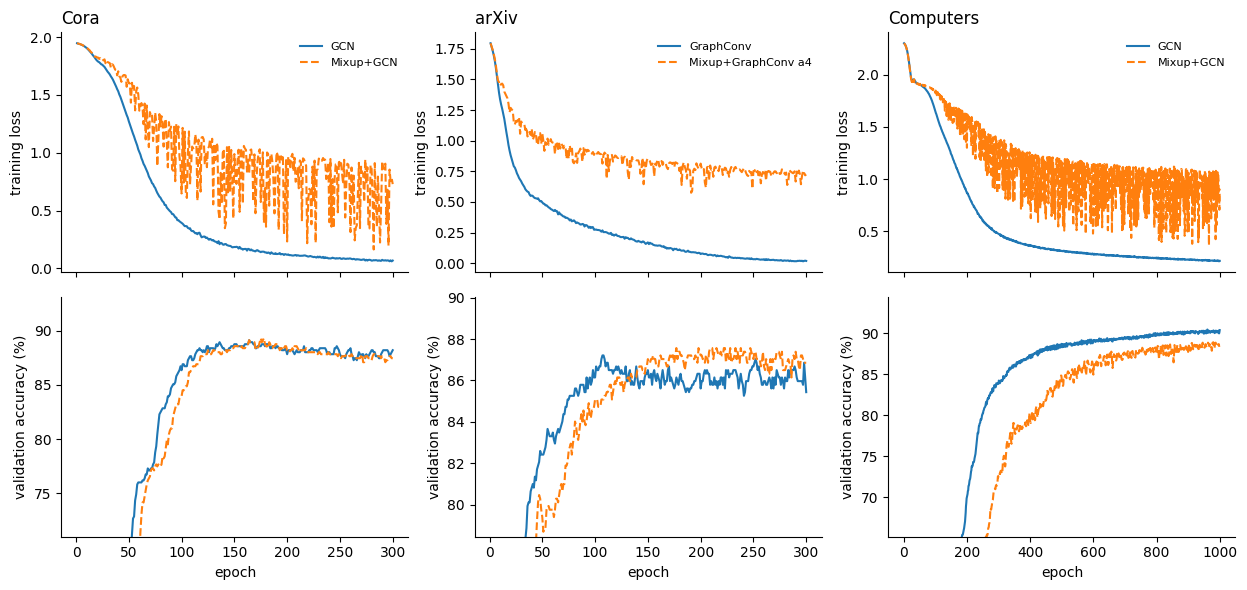

In [52]:
CURVES = [('Cora', 'GCN', 'Mixup+GCN', HP['epochs']),
          ('arXiv', 'GraphConv', 'Mixup+GraphConv a4', HP['epochs']),
          ('Computers' if 'Computers' in AMZ_DATASETS else AMZ_DATASETS[0], 'GCN', 'Mixup+GCN', AMZ_EPOCHS)]
if RUN_CURVES:
    CURVE_PATH = osp.join(OUT, 'curves_quick.json' if QUICK else 'curves.json')
    curves = json.load(open(CURVE_PATH)) if osp.exists(CURVE_PATH) else {}
    for d, base, mix, ep in CURVES:
        D = load_dataset(d)
        for m in (base, mix):
            k = f'{d}|{m}|{ep}'
            if k not in curves:
                curves[k] = train_node(D, make_split(D.n, 0), m, 2, seed=0, hp=dict(HP, epochs=ep), history=True)['history']
                json.dump(curves, open(CURVE_PATH, 'w'))
    fig, axes = plt.subplots(2, len(CURVES), figsize=(4.2 * len(CURVES), 6), sharex='col')
    for j, (d, base, mix, ep) in enumerate(CURVES):
        for m, ls in ((base, '-'), (mix, '--')):
            h = np.array(curves[f'{d}|{m}|{ep}'])
            axes[0, j].plot(h[:, 0], h[:, 1], ls, label=m)
            axes[1, j].plot(h[:, 0], 100 * h[:, 2], ls, label=m)
        axes[0, j].set_title(d, loc='left')
        axes[0, j].set_ylabel('training loss')
        axes[1, j].set_ylabel('validation accuracy (%)')
        axes[1, j].set_xlabel('epoch')
        axes[0, j].legend(frameon=False, fontsize=8)
        lo = np.percentile(100 * np.array(curves[f'{d}|{base}|{ep}'])[:, 2], 20)
        axes[1, j].set_ylim(max(0, lo - 5), None)
        for a in axes[:, j]:
            a.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    save_fig(fig, 'training_curves')

---
## 9. Export
Every table (CSV + LaTeX) and figure (PNG + PDF) is in `step4/tables` and `step4/figures` on Drive. This cell also packs them, with the result files, into `step4_outputs.zip` for the GitHub repo (`results/`). The answer key and the Gemini cache are included; your API key never touches any file.

In [53]:
zip_base = osp.join(OUT, 'step4_outputs')
stage = osp.join('/tmp', 'step4_outputs')
shutil.rmtree(stage, ignore_errors=True)
shutil.copytree(TAB, osp.join(stage, 'tables'))
shutil.copytree(FIG, osp.join(stage, 'figures'))
for f in ['step4_results.jsonl', 'llm_cache.jsonl', 'blind_key.csv', 'curves.json', 'blind_sheet_you.xlsx', 'blind_sheet_helper.xlsx']:
    if osp.exists(osp.join(OUT, f)):
        shutil.copy(osp.join(OUT, f), stage)
shutil.make_archive(zip_base, 'zip', stage)
print('written', zip_base + '.zip')
print('tables :', sorted(os.listdir(TAB)))
print('figures:', sorted(f for f in os.listdir(FIG) if f.endswith('.png')))
print('\nEnvironment for the report:', ENV, '| Gemini model:', GEMINI_MODEL if RUN_LLM else '-',
      f'| Gemini requests this session: {LLM_REQUESTS}')

written /content/drive/MyDrive/mixup_reproduction/step4/step4_outputs.zip
tables : ['agreement_all_raters.csv', 'agreement_all_raters.tex', 'agreement_fleiss.csv', 'agreement_fleiss.tex', 'agreement_human.csv', 'agreement_human.tex', 'alpha_layer_gains.csv', 'alpha_layer_gains.tex', 'alpha_layer_results.csv', 'alpha_layer_results.tex', 'amazon_convergence.csv', 'amazon_convergence.tex', 'amazon_convergence_gains.csv', 'amazon_convergence_gains.tex', 'annotation_disagreements.csv', 'annotation_disagreements.tex', 'arxiv_label_rate.csv', 'arxiv_label_rate.tex', 'arxiv_label_rate_gains.csv', 'arxiv_label_rate_gains.tex', 'arxiv_mixup_gains.csv', 'arxiv_mixup_gains.tex', 'arxiv_per_class_f1.csv', 'arxiv_per_class_f1.tex', 'arxiv_results.csv', 'arxiv_results.tex', 'dataset_statistics.csv', 'dataset_statistics.tex', 'errors_by_cross_listing.csv', 'errors_by_cross_listing.tex', 'errors_by_local_homophily.csv', 'errors_by_local_homophily.tex', 'gemini_judge_control.csv', 'gemini_judge_errors.c